In [3]:
from pathlib import Path
import tarfile

nih_dir = Path("datasets") / "NIH_ChestXray14"
archive_dir = nih_dir / "archives"

for tar_path in sorted(archive_dir.glob("*.tar")):
    try:
        with tarfile.open(tar_path, "r:") as tar:
            print(f"{tar_path.name}: {len(tar.getmembers())} entries")
    except Exception as e:
        print(f"{tar_path.name}: ERROR - {e}")

In [4]:
from pathlib import Path

nih_dir = Path("datasets") / "NIH_ChestXray14"
archive_dir = nih_dir / "archives"

print("Notebook working directory:")
print(Path.cwd())

print("\nNIH folder exists:", nih_dir.exists())
print("Archive folder exists:", archive_dir.exists())

if nih_dir.exists():
    print("\nFiles/folders inside NIH folder:")
    for item in nih_dir.iterdir():
        print(item.name)

if archive_dir.exists():
    print("\nTAR files found:", len(list(archive_dir.glob("*.tar"))))
    for item in archive_dir.glob("*.tar"):
        print(item.name)

Notebook working directory:
c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main

NIH folder exists: True
Archive folder exists: True

Files/folders inside NIH folder:
archives
batch_download_zips.py
Data_Entry_2017_v2020.csv
effusion_image_list.csv
test_list.txt
train_val_list.txt

TAR files found: 0


In [5]:
from pathlib import Path

project_dir = Path.cwd()

print("Searching for NIH archive files...\n")

for pattern in ["*.tar", "*.tar.gz", "*.zip"]:
    matches = list(project_dir.rglob(pattern))
    print(f"\n{pattern} files found: {len(matches)}")

    for path in matches[:20]:
        print(path)

Searching for NIH archive files...


*.tar files found: 0

*.tar.gz files found: 12
c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\NIH_ChestXray14\archives\images_001.tar.gz
c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\NIH_ChestXray14\archives\images_002.tar.gz
c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\NIH_ChestXray14\archives\images_003.tar.gz
c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\NIH_ChestXray14\archives\images_004.tar.gz
c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\NIH_ChestXray14\archives\images_005.tar.gz
c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\NIH_ChestXray14\archives\images_006.tar.gz
c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\NIH_ChestXray14\archives\images_007.tar.gz
c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\NIH_ChestXray14\archives\images_008.tar.gz
c:\mini project\TB-Detection-Hybrid-

In [6]:
from pathlib import Path
import tarfile

nih_dir = Path("datasets") / "NIH_ChestXray14"
archive_dir = nih_dir / "archives"

tar_path = archive_dir / "images_001.tar.gz"

print("Archive exists:", tar_path.exists())

with tarfile.open(tar_path, "r:gz") as tar:
    members = tar.getnames()
    print("Number of entries:", len(members))
    print("\nFirst 10 entries:")
    for name in members[:10]:
        print(name)

Archive exists: True
Number of entries: 5000

First 10 entries:
images/00001075_000.png
images/00001151_006.png
images/00000583_047.png
images/00000830_002.png
images/00001232_004.png
images/00000245_001.png
images/00000089_000.png
images/00000911_000.png
images/00000811_000.png
images/00001213_002.png


In [7]:
from pathlib import Path
import tarfile
import pandas as pd

nih_dir = Path("datasets") / "NIH_ChestXray14"
archive_dir = nih_dir / "archives"

# Load the list of NIH images labeled Effusion
effusion_df = pd.read_csv(nih_dir / "effusion_image_list.csv")
effusion_names = set(effusion_df["Image Index"])

print("Effusion filenames in CSV:", len(effusion_names))

# Check each archive without extracting images
for archive_path in sorted(archive_dir.glob("*.tar.gz")):
    with tarfile.open(archive_path, "r:gz") as tar:
        image_names = {
            Path(member.name).name
            for member in tar.getmembers()
            if member.isfile() and member.name.lower().endswith(".png")
        }

    matches = image_names & effusion_names
    print(f"{archive_path.name}: {len(matches)} Effusion-labeled images")

Effusion filenames in CSV: 13317
images_001.tar.gz: 487 Effusion-labeled images
images_002.tar.gz: 895 Effusion-labeled images
images_003.tar.gz: 950 Effusion-labeled images
images_004.tar.gz: 1038 Effusion-labeled images
images_005.tar.gz: 1215 Effusion-labeled images
images_006.tar.gz: 1306 Effusion-labeled images
images_007.tar.gz: 1351 Effusion-labeled images
images_008.tar.gz: 1325 Effusion-labeled images
images_009.tar.gz: 1325 Effusion-labeled images
images_010.tar.gz: 1182 Effusion-labeled images
images_011.tar.gz: 1266 Effusion-labeled images
images_012.tar.gz: 977 Effusion-labeled images


In [8]:
from pathlib import Path
import pandas as pd

nih_dir = Path("datasets") / "NIH_ChestXray14"

df = pd.read_csv(nih_dir / "Data_Entry_2017_v2020.csv")

# Images labeled only as Effusion
pure_effusion_df = df[
    df["Finding Labels"].fillna("").str.strip().eq("Effusion")
].copy()

print("Images labeled only Effusion:", len(pure_effusion_df))
print("Unique patients:", pure_effusion_df["Patient ID"].nunique())

display(pure_effusion_df[
    ["Image Index", "Finding Labels", "Patient ID"]
].head())

Images labeled only Effusion: 3955
Unique patients: 1984


,Image Index,Finding Labels,Patient ID
28,00000011_000.png,Effusion,11
84,00000013_021.png,Effusion,13
106,00000025_000.png,Effusion,25
194,00000039_004.png,Effusion,39
205,00000041_006.png,Effusion,41


In [11]:

from pathlib import Path
import pandas as pd
import tarfile

PROJECT_DIR = Path.cwd()
NIH_DIR = PROJECT_DIR / "Datasets" / "NIH_ChestXray14"
ARCHIVE_DIR = NIH_DIR / "archives"
OUTPUT_DIR = NIH_DIR / "effusion_images"

metadata_path = NIH_DIR / "Data_Entry_2017_v2020.csv"
df = pd.read_csv(metadata_path)

# Select only images whose recorded finding is exactly "Effusion"
pure_effusion = df[
    df["Finding Labels"].fillna("").str.strip().eq("Effusion")
].copy()

# Select up to 1,000 images reproducibly
selected_df = pure_effusion.sample(
    n=min(1000, len(pure_effusion)),
    random_state=42
)

selected_names = set(selected_df["Image Index"])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Keep any matching files already extracted
extracted_names = {
    p.name for p in OUTPUT_DIR.iterdir()
    if p.is_file() and p.name in selected_names
}

print("Effusion images selected:", len(selected_names))
print("Already extracted:", len(extracted_names))

# Search each compressed archive and extract only selected images
for archive_path in sorted(ARCHIVE_DIR.glob("images_*.tar.gz")):
    if len(extracted_names) == len(selected_names):
        break

    print("\nChecking:", archive_path.name)

    with tarfile.open(archive_path, "r:gz") as tar:
        for member in tar:
            if not member.isfile():
                continue

            filename = Path(member.name).name

            if filename not in selected_names:
                continue
            if filename in extracted_names:
                continue

            source = tar.extractfile(member)
            if source is None:
                continue

            destination = OUTPUT_DIR / filename
            with source, destination.open("wb") as target:
                target.write(source.read())

            extracted_names.add(filename)

    print("Matching images extracted:", len(extracted_names))

# Save metadata for the images that were actually extracted
extracted_df = selected_df[
    selected_df["Image Index"].isin(extracted_names)
].copy()

extracted_df.to_csv(
    NIH_DIR / "selected_effusion_metadata.csv",
    index=False
)

print("\nEXTRACTION SUMMARY")
print("Selected:", len(selected_names))
print("Extracted:", len(extracted_names))
print("Output folder:", OUTPUT_DIR)
print("Metadata:", NIH_DIR / "selected_effusion_metadata.csv")

if len(extracted_names) < len(selected_names):
    print("WARNING: Some selected images were not found in the archives.")


Effusion images selected: 1000
Already extracted: 0

Checking: images_001.tar.gz
Matching images extracted: 41

Checking: images_002.tar.gz
Matching images extracted: 140

Checking: images_003.tar.gz
Matching images extracted: 218

Checking: images_004.tar.gz
Matching images extracted: 312

Checking: images_005.tar.gz
Matching images extracted: 417

Checking: images_006.tar.gz
Matching images extracted: 511

Checking: images_007.tar.gz
Matching images extracted: 594

Checking: images_008.tar.gz
Matching images extracted: 695

Checking: images_009.tar.gz
Matching images extracted: 763

Checking: images_010.tar.gz
Matching images extracted: 833

Checking: images_011.tar.gz
Matching images extracted: 926

Checking: images_012.tar.gz
Matching images extracted: 1000

EXTRACTION SUMMARY
Selected: 1000
Extracted: 1000
Output folder: c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\NIH_ChestXray14\effusion_images
Metadata: c:\mini project\TB-Detection-Hybrid-CNN-Transformers-

In [12]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd()
DATASETS_DIR = PROJECT_DIR / "Datasets"
NIH_DIR = DATASETS_DIR / "NIH_ChestXray14"

IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp"}

CLASS_NAMES = [
    "Normal",
    "Tuberculosis",
    "COVID-19",
    "Viral Pneumonia",
    "Lung Opacity",
    "Pleural Effusion",
]

CLASS_TO_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}

# Use one Normal source to avoid duplicate Normal images.
class_folders = {
    "Normal": DATASETS_DIR / "TB_Chest_Radiography_Database" / "Normal",
    "Tuberculosis": DATASETS_DIR / "TB_Chest_Radiography_Database" / "Tuberculosis",
    "COVID-19": DATASETS_DIR / "COVID-19_Radiography_Dataset" / "COVID",
    "Viral Pneumonia": DATASETS_DIR / "COVID-19_Radiography_Dataset" / "Viral Pneumonia",
    "Lung Opacity": DATASETS_DIR / "COVID-19_Radiography_Dataset" / "Lung_Opacity",
    "Pleural Effusion": NIH_DIR / "effusion_images",
}

records = []

for class_name, folder in class_folders.items():
    if not folder.exists():
        raise FileNotFoundError(f"Missing folder: {folder}")

    image_paths = sorted(
        p for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    print(f"{class_name}: {len(image_paths):,} images")

    for path in image_paths:
        records.append({
            "image_path": str(path.resolve()),
            "class_name": class_name,
            "label": CLASS_TO_ID[class_name],
        })

index_df = pd.DataFrame(records)

# Validate the index
if index_df.empty:
    raise ValueError("No images were found. Check the dataset paths.")

if index_df["image_path"].duplicated().any():
    duplicates = index_df.loc[
        index_df["image_path"].duplicated(), "image_path"
    ]
    raise ValueError(f"Duplicate image paths found: {len(duplicates)}")

missing_paths = [
    path for path in index_df["image_path"]
    if not Path(path).is_file()
]

if missing_paths:
    raise FileNotFoundError(
        f"{len(missing_paths)} indexed image files are missing."
    )

output_csv = DATASETS_DIR / "six_class_index.csv"
index_df.to_csv(output_csv, index=False)

print("\nClass label mapping:")
print(CLASS_TO_ID)

print("\nFinal class counts:")
print(index_df["class_name"].value_counts().reindex(CLASS_NAMES))

print("\nTotal indexed images:", f"{len(index_df):,}")
print("Saved index:", output_csv)
print("Validation passed: all indexed paths exist and are unique.")


Normal: 3,500 images
Tuberculosis: 700 images
COVID-19: 7,232 images
Viral Pneumonia: 2,690 images
Lung Opacity: 12,024 images
Pleural Effusion: 1,000 images

Class label mapping:
{'Normal': 0, 'Tuberculosis': 1, 'COVID-19': 2, 'Viral Pneumonia': 3, 'Lung Opacity': 4, 'Pleural Effusion': 5}

Final class counts:
class_name
Normal               3500
Tuberculosis          700
COVID-19             7232
Viral Pneumonia      2690
Lung Opacity        12024
Pleural Effusion     1000
Name: count, dtype: int64

Total indexed images: 27,146
Saved index: c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\six_class_index.csv
Validation passed: all indexed paths exist and are unique.


In [15]:

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# --------------------------------------------------
# 1. Define paths and load the six-class index
# --------------------------------------------------
PROJECT_DIR = Path.cwd()
DATASETS_DIR = PROJECT_DIR / "Datasets"
NIH_DIR = DATASETS_DIR / "NIH_ChestXray14"

index_path = DATASETS_DIR / "six_class_index.csv"
metadata_path = NIH_DIR / "selected_effusion_metadata.csv"

index_df = pd.read_csv(index_path)
nih_metadata = pd.read_csv(metadata_path)

print("Total indexed images:", len(index_df))

# --------------------------------------------------
# 2. Attach NIH patient IDs to Effusion images
# --------------------------------------------------
patient_lookup = (
    nih_metadata
    .drop_duplicates(subset="Image Index")
    .set_index("Image Index")["Patient ID"]
    .to_dict()
)

def get_patient_id(row):
    if row["class_name"] == "Pleural Effusion":
        return patient_lookup.get(Path(row["image_path"]).name, "")
    return ""

index_df["patient_id"] = index_df.apply(get_patient_id, axis=1)
index_df["patient_id"] = index_df["patient_id"].fillna("").astype(str)

effusion_rows = index_df[
    index_df["class_name"] == "Pleural Effusion"
].copy()

if effusion_rows["patient_id"].eq("").any():
    missing_count = int(effusion_rows["patient_id"].eq("").sum())
    raise ValueError(
        f"{missing_count} Effusion images are missing patient IDs. "
        "Check selected_effusion_metadata.csv."
    )

# --------------------------------------------------
# 3. Split Effusion by patient
# --------------------------------------------------
nih_patients = np.array(
    effusion_rows["patient_id"].unique().tolist(),
    dtype=str
)

print("Unique NIH patients:", len(nih_patients))

if len(nih_patients) < 3:
    raise ValueError(
        "Not enough unique NIH patients to create three splits."
    )

train_patients, temp_patients = train_test_split(
    nih_patients.tolist(),
    test_size=0.30,
    random_state=42
)

val_patients, test_patients = train_test_split(
    temp_patients,
    test_size=0.50,
    random_state=42
)

nih_train = effusion_rows[
    effusion_rows["patient_id"].isin(train_patients)
].copy()

nih_val = effusion_rows[
    effusion_rows["patient_id"].isin(val_patients)
].copy()

nih_test = effusion_rows[
    effusion_rows["patient_id"].isin(test_patients)
].copy()

# --------------------------------------------------
# 4. Split the other five classes
# --------------------------------------------------
other_rows = index_df[
    index_df["class_name"] != "Pleural Effusion"
].copy()

other_train, other_temp = train_test_split(
    other_rows,
    test_size=0.30,
    stratify=other_rows["label"],
    random_state=42
)

other_val, other_test = train_test_split(
    other_temp,
    test_size=0.50,
    stratify=other_temp["label"],
    random_state=42
)

# --------------------------------------------------
# 5. Combine the splits
# --------------------------------------------------
train_df = pd.concat(
    [other_train, nih_train], ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

val_df = pd.concat(
    [other_val, nih_val], ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

test_df = pd.concat(
    [other_test, nih_test], ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

# --------------------------------------------------
# 6. Check image-path separation
# --------------------------------------------------
train_paths = set(train_df["image_path"])
val_paths = set(val_df["image_path"])
test_paths = set(test_df["image_path"])

assert train_paths.isdisjoint(val_paths), "Train/validation path overlap!"
assert train_paths.isdisjoint(test_paths), "Train/test path overlap!"
assert val_paths.isdisjoint(test_paths), "Validation/test path overlap!"

# Check NIH patient separation
train_nih_ids = set(nih_train["patient_id"])
val_nih_ids = set(nih_val["patient_id"])
test_nih_ids = set(nih_test["patient_id"])

assert train_nih_ids.isdisjoint(val_nih_ids), "NIH patient leakage!"
assert train_nih_ids.isdisjoint(test_nih_ids), "NIH patient leakage!"
assert val_nih_ids.isdisjoint(test_nih_ids), "NIH patient leakage!"

# Confirm that every indexed image appears in exactly one split
assert len(train_df) + len(val_df) + len(test_df) == len(index_df)

# --------------------------------------------------
# 7. Save the split CSV files
# --------------------------------------------------
train_df.to_csv(DATASETS_DIR / "train_split.csv", index=False)
val_df.to_csv(DATASETS_DIR / "validation_split.csv", index=False)
test_df.to_csv(DATASETS_DIR / "test_split.csv", index=False)

# --------------------------------------------------
# 8. Print summary
# --------------------------------------------------
print("\nSPLIT SIZES")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

print("\nCLASS COUNTS BY SPLIT")
for split_name, split_df in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n{split_name}")
    print(
        split_df["class_name"]
        .value_counts()
        .reindex(
            [
                "Normal",
                "Tuberculosis",
                "COVID-19",
                "Viral Pneumonia",
                "Lung Opacity",
                "Pleural Effusion"
            ],
            fill_value=0
        )
    )

print("\nNIH UNIQUE PATIENTS BY SPLIT")
print("Train:", len(train_nih_ids))
print("Validation:", len(val_nih_ids))
print("Test:", len(test_nih_ids))

print("\nSUCCESS: image paths and NIH patient IDs do not overlap between splits.")
print("Saved files:")
print(DATASETS_DIR / "train_split.csv")
print(DATASETS_DIR / "validation_split.csv")
print(DATASETS_DIR / "test_split.csv")


Total indexed images: 27146
Unique NIH patients: 766

SPLIT SIZES
Train: 19006
Validation: 4075
Test: 4065
Total: 27146

CLASS COUNTS BY SPLIT

TRAIN
class_name
Normal              2450
Tuberculosis         490
COVID-19            5062
Viral Pneumonia     1883
Lung Opacity        8417
Pleural Effusion     704
Name: count, dtype: int64

VALIDATION
class_name
Normal               525
Tuberculosis         105
COVID-19            1085
Viral Pneumonia      403
Lung Opacity        1804
Pleural Effusion     153
Name: count, dtype: int64

TEST
class_name
Normal               525
Tuberculosis         105
COVID-19            1085
Viral Pneumonia      404
Lung Opacity        1803
Pleural Effusion     143
Name: count, dtype: int64

NIH UNIQUE PATIENTS BY SPLIT
Train: 536
Validation: 115
Test: 115

SUCCESS: image paths and NIH patient IDs do not overlap between splits.
Saved files:
c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\train_split.csv
c:\mini project\TB-Detection-Hybrid

In [16]:

from pathlib import Path
import pandas as pd

DATASETS_DIR = Path.cwd() / "Datasets"

split_files = {
    "Train": DATASETS_DIR / "train_split.csv",
    "Validation": DATASETS_DIR / "validation_split.csv",
    "Test": DATASETS_DIR / "test_split.csv",
}

expected_classes = [
    "Normal",
    "Tuberculosis",
    "COVID-19",
    "Viral Pneumonia",
    "Lung Opacity",
    "Pleural Effusion",
]

split_data = {}

for split_name, csv_path in split_files.items():
    if not csv_path.exists():
        raise FileNotFoundError(f"Missing split file: {csv_path}")

    df = pd.read_csv(csv_path)
    split_data[split_name] = df

    print(f"\n{split_name}: {len(df):,} images")
    print(
        df["class_name"]
        .value_counts()
        .reindex(expected_classes, fill_value=0)
        .to_string()
    )

# Check image paths don't overlap across splits
train_paths = set(split_data["Train"]["image_path"])
val_paths = set(split_data["Validation"]["image_path"])
test_paths = set(split_data["Test"]["image_path"])

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)

# Check that every class is represented in each split
for split_name, df in split_data.items():
    missing_classes = set(expected_classes) - set(df["class_name"])
    if missing_classes:
        raise ValueError(
            f"{split_name} is missing classes: {missing_classes}"
        )

print("\nSUCCESS: all split files exist.")
print("SUCCESS: all six classes are present in every split.")
print("SUCCESS: no image paths overlap across splits.")



Train: 19,006 images
class_name
Normal              2450
Tuberculosis         490
COVID-19            5062
Viral Pneumonia     1883
Lung Opacity        8417
Pleural Effusion     704

Validation: 4,075 images
class_name
Normal               525
Tuberculosis         105
COVID-19            1085
Viral Pneumonia      403
Lung Opacity        1804
Pleural Effusion     153

Test: 4,065 images
class_name
Normal               525
Tuberculosis         105
COVID-19            1085
Viral Pneumonia      404
Lung Opacity        1803
Pleural Effusion     143

SUCCESS: all split files exist.
SUCCESS: all six classes are present in every split.
SUCCESS: no image paths overlap across splits.


In [17]:

from pathlib import Path
import pandas as pd
import tensorflow as tf

# ---------------------------------------
# 1. Configuration
# ---------------------------------------
PROJECT_DIR = Path.cwd()
DATASETS_DIR = PROJECT_DIR / "Datasets"

IMG_SIZE = 224
BATCH_SIZE = 16
NUM_CLASSES = 6
AUTOTUNE = tf.data.AUTOTUNE

CLASS_NAMES = [
    "Normal",
    "Tuberculosis",
    "COVID-19",
    "Viral Pneumonia",
    "Lung Opacity",
    "Pleural Effusion",
]

# ---------------------------------------
# 2. Load saved split CSV files
# ---------------------------------------
train_df = pd.read_csv(DATASETS_DIR / "train_split.csv")
val_df = pd.read_csv(DATASETS_DIR / "validation_split.csv")
test_df = pd.read_csv(DATASETS_DIR / "test_split.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

# ---------------------------------------
# 3. Verify labels and paths
# ---------------------------------------
for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    if not df["label"].between(0, NUM_CLASSES - 1).all():
        raise ValueError(f"{name} contains invalid labels.")

    missing = [
        p for p in df["image_path"]
        if not Path(p).is_file()
    ]
    if missing:
        raise FileNotFoundError(
            f"{name} has {len(missing)} missing image files."
        )

# ---------------------------------------
# 4. Define image loader
# ---------------------------------------
def load_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    # Keep pixels in the 0–255 range.
    # MobileNetV2 preprocessing will be applied
    # in the model itself.
    image = tf.cast(image, tf.float32)

    label = tf.cast(label, tf.int32)

    return image, label

# ---------------------------------------
# 5. Create tf.data datasets
# ---------------------------------------
def make_dataset(df, training=False):
    paths = df["image_path"].astype(str).to_numpy()
    labels = df["label"].astype("int32").to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(df), 5000),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("\nDatasets created successfully.")

# ---------------------------------------
# 6. Inspect one batch
# ---------------------------------------
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Label dtype:", labels.dtype)
    print("Pixel value range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))
    print("Labels in sample batch:", labels.numpy())

print("\nImage pipeline check complete.")


Train: 19006
Validation: 4075
Test: 4065

Datasets created successfully.
Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int32'>
Pixel value range: 0.0 to 255.0
Labels in sample batch: [2 4 4 2 4 2 4 2 2 1 4 2 3 4 3 4]

Image pipeline check complete.


In [22]:

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2

IMG_SIZE = 224
NUM_CLASSES = 6

# ---------------------------------------
# Transformer encoder
# ---------------------------------------
def transformer_encoder(x, num_heads=4, key_dim=64,
                        mlp_dim=256, dropout=0.1):
    attention_output = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=key_dim,
        dropout=dropout
    )(x, x)

    x = layers.Add()([x, attention_output])
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    ff = layers.Dense(mlp_dim, activation="gelu")(x)
    ff = layers.Dropout(dropout)(ff)
    ff = layers.Dense(256)(ff)

    x = layers.Add()([x, ff])
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    return x


# ---------------------------------------
# Positional embedding with correct batch shape
# ---------------------------------------
@tf.keras.utils.register_keras_serializable()
class AddPositionEmbedding(layers.Layer):
    def build(self, input_shape):
        self.num_tokens = input_shape[1]
        self.embedding_dim = input_shape[2]

        self.position_embeddings = self.add_weight(
            name="position_embeddings",
            shape=(self.num_tokens, self.embedding_dim),
            initializer="random_normal",
            trainable=True
        )

    def call(self, inputs):
        position_embeddings = tf.expand_dims(
            self.position_embeddings, axis=0
        )
        return inputs + position_embeddings


# ---------------------------------------
# Build the hybrid model
# ---------------------------------------
inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="chest_xray_image"
)

preprocessed = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

cnn_base = MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
cnn_base.trainable = False

feature_map = cnn_base(preprocessed, training=False)

# 7x7 spatial map becomes 49 tokens
tokens = layers.Reshape((-1, 1280), name="spatial_tokens")(feature_map)
tokens = layers.Dense(256, name="token_projection")(tokens)
tokens = AddPositionEmbedding(name="position_embedding")(tokens)

tokens = transformer_encoder(tokens)

transformer_features = layers.GlobalAveragePooling1D()(tokens)
cnn_features = layers.GlobalAveragePooling2D()(feature_map)

combined = layers.Concatenate()([
    cnn_features,
    transformer_features
])

combined = layers.Dense(256, activation="relu")(combined)
combined = layers.BatchNormalization()(combined)
combined = layers.Dropout(0.4)(combined)

combined = layers.Dense(128, activation="relu")(combined)
combined = layers.Dropout(0.3)(combined)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="class_probabilities"
)(combined)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="hybrid_cnn_transformer"
)

model.summary()
print("Model output shape:", model.output_shape)


Model: "hybrid_cnn_transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ chest_xray_image    │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ true_divide_1       │ (None, 224, 224,  │          0 │ chest_xray_image… │
│ (TrueDivide)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subtract_1          │ (None, 224, 224,  │          0 │ true_divide_1[0]… │
│ (Subtract)          │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ subtract_1[0][0]  │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_tokens      │ (None, 49, 1280)  │          0 │ mobilenetv2_1.00… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_projection    │ (None, 49, 256)   │    327,936 │ spatial_tokens[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ position_embedding  │ (None, 49, 256)   │     12,544 │ token_projection… │
│ (AddPositionEmbedd… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 49, 256)   │    263,168 │ position_embeddi… │
│ (MultiHeadAttentio… │                   │            │ position_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 49, 256)   │          0 │ position_embeddi… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 49, 256)   │        512 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 49, 256)   │     65,792 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 49, 256)   │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 49, 256)   │     65,792 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_4 (Add)         │ (None, 49, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 49, 256)   │        512 │ add_4[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 256)       │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 1536)      │          0 │ global_average_p

 Total params: 3,422,406 (13.06 MB)

 Trainable params: 1,163,910 (4.44 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

Model output shape: (None, 6)


In [23]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Corrected model compiled successfully.")


Corrected model compiled successfully.


In [24]:

for images, labels in train_ds.take(1):
    predictions = model(images, training=False)

    print("Images:", images.shape)
    print("Labels:", labels.shape)
    print("Predictions:", predictions.shape)
    print("All predictions finite:",
          bool(tf.reduce_all(tf.math.is_finite(predictions))))

    assert predictions.shape == (images.shape[0], 6)
    assert bool(tf.reduce_all(tf.math.is_finite(predictions)))

print("Forward-pass test passed.")


Images: (16, 224, 224, 3)
Labels: (16,)
Predictions: (16, 6)
All predictions finite: True
Forward-pass test passed.


In [19]:
from pathlib import Path
import numpy as np
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

# ---------------------------------------
# 1. Configuration
# ---------------------------------------
NUM_CLASSES = 6

CLASS_NAMES = [
    "Normal",
    "Tuberculosis",
    "COVID-19",
    "Viral Pneumonia",
    "Lung Opacity",
    "Pleural Effusion",
]

# ---------------------------------------
# 2. Calculate class weights
# ---------------------------------------
train_labels = train_df["label"].to_numpy(dtype=np.int32)

classes = np.arange(NUM_CLASSES)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_labels
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

print("Class weights:")
for class_id, weight in class_weights.items():
    print(f"{CLASS_NAMES[class_id]}: {weight:.3f}")

# ---------------------------------------
# 3. Compile six-class model
# ---------------------------------------
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-4
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ---------------------------------------
# 4. Configure callbacks
# ---------------------------------------
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(
        (Path.cwd() / "chest_xray_6class_best.keras").resolve()
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

print("\nModel compiled successfully.")
print("Loss: sparse_categorical_crossentropy")
print("Optimizer: Adam")
print("Initial learning rate: 0.0001")
print("Callbacks configured.")


Class weights:
Normal: 1.293
Tuberculosis: 6.465
COVID-19: 0.626
Viral Pneumonia: 1.682
Lung Opacity: 0.376
Pleural Effusion: 4.500

Model compiled successfully.
Loss: sparse_categorical_crossentropy
Optimizer: Adam
Initial learning rate: 0.0001
Callbacks configured.


In [25]:

import time
from pathlib import Path

EPOCHS = 10

checkpoint_path = Path.cwd() / "chest_xray_6class_best.keras"

# Make sure the checkpoint callback points to the corrected model's file.
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(checkpoint_path),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

start_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint
    ],
    verbose=1
)

elapsed_minutes = (time.time() - start_time) / 60

print(f"\nTraining finished in {elapsed_minutes:.1f} minutes.")
print("Best checkpoint:", checkpoint_path.resolve())


Epoch 1/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.4537 - loss: 1.2170
Epoch 1: val_loss improved from None to 0.49114, saving model to c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\chest_xray_6class_best.keras

Epoch 1: finished saving model to c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\chest_xray_6class_best.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 267s 221ms/step - accuracy: 0.5838 - loss: 0.8773 - val_accuracy: 0.7941 - val_loss: 0.4911 - learning_rate: 1.0000e-04
Epoch 2/10
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - accuracy: 0.7349 - loss: 0.4933
Epoch 2: val_loss improved from 0.49114 to 0.49093, saving model to c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\chest_xray_6class_best.keras

Epoch 2: finished saving model to c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\chest_xray_6class_best.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 271s 228ms/step - accuracy: 0.7491 - loss: 0.4577 - val_accuracy: 0.7998 - val_loss: 0.

In [26]:

import tensorflow as tf
from pathlib import Path

# Make sure the custom layer is defined in this notebook session.
# If you already defined AddPositionEmbedding, this reuses it.

checkpoint_path = Path.cwd() / "chest_xray_6class_best.keras"

if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"Checkpoint not found: {checkpoint_path}"
    )

# Load the best saved model
best_model = tf.keras.models.load_model(
    checkpoint_path,
    compile=False
)

# Test a fresh batch
for images, labels in test_ds.take(1):
    predictions = best_model(images, training=False)

    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Predictions shape:", predictions.shape)
    print(
        "Predictions finite:",
        bool(tf.reduce_all(tf.math.is_finite(predictions)))
    )

    assert predictions.shape == (images.shape[0], 6)
    assert bool(tf.reduce_all(tf.math.is_finite(predictions)))

print("\nSaved model loaded and forward-pass test passed.")


Images shape: (16, 224, 224, 3)
Labels shape: (16,)
Predictions shape: (16, 6)
Predictions finite: True

Saved model loaded and forward-pass test passed.


Test accuracy: 0.8802
Test accuracy: 88.02%

CLASSIFICATION REPORT

                  precision    recall  f1-score   support

          Normal     0.9616    0.9543    0.9579       525
    Tuberculosis     0.9115    0.9810    0.9450       105
        COVID-19     0.8059    0.8037    0.8048      1085
 Viral Pneumonia     0.9680    0.9728    0.9704       404
    Lung Opacity     0.8830    0.8791    0.8810      1803
Pleural Effusion     0.8378    0.8671    0.8522       143

        accuracy                         0.8802      4065
       macro avg     0.8946    0.9097    0.9019      4065
    weighted avg     0.8802    0.8802    0.8801      4065



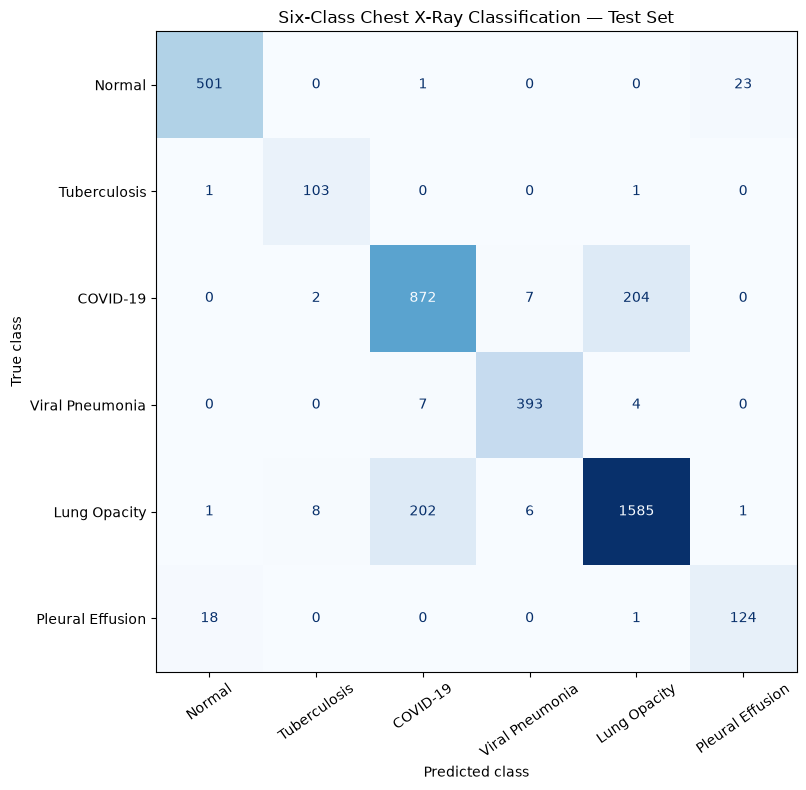

Confusion matrix shape: (6, 6)


In [28]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    ConfusionMatrixDisplay
)

CLASS_NAMES = [
    "Normal",
    "Tuberculosis",
    "COVID-19",
    "Viral Pneumonia",
    "Lung Opacity",
    "Pleural Effusion",
]

# Use the saved best model and held-out test dataset
y_true = []
y_pred = []
y_prob = []

for images, labels in test_ds:
    probabilities = best_model.predict(images, verbose=0)
    predicted_labels = np.argmax(probabilities, axis=1)

    y_true.extend(labels.numpy().tolist())
    y_pred.extend(predicted_labels.tolist())
    y_prob.extend(probabilities.tolist())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

# ---------------------------------------
# 1. Overall test accuracy
# ---------------------------------------
test_accuracy = accuracy_score(y_true, y_pred)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

# ---------------------------------------
# 2. Per-class classification report
# ---------------------------------------
print("\nCLASSIFICATION REPORT\n")

print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

# ---------------------------------------
# 3. Confusion matrix
# ---------------------------------------
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

fig, ax = plt.subplots(figsize=(10, 8))

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=35,
    colorbar=False
)

ax.set_title("Six-Class Chest X-Ray Classification — Test Set")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")

plt.tight_layout()
plt.show()

print("Confusion matrix shape:", cm.shape)


In [29]:

import tensorflow as tf
from pathlib import Path

# ---------------------------------------
# 1. Unfreeze only the top CNN layers
# ---------------------------------------
cnn_base.trainable = True

# Freeze most layers; fine-tune only the last 30.
for layer in cnn_base.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability.
for layer in cnn_base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Trainable CNN layers:",
      sum(layer.trainable for layer in cnn_base.layers))
print("Total CNN layers:", len(cnn_base.layers))

# ---------------------------------------
# 2. Recompile with a lower learning rate
# ---------------------------------------
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ---------------------------------------
# 3. Fine-tuning callbacks
# ---------------------------------------
fine_tune_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(
        (Path.cwd() / "chest_xray_6class_finetuned_best.keras").resolve()
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

fine_tune_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

fine_tune_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# ---------------------------------------
# 4. Fine-tune
# ---------------------------------------
history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weights,
    callbacks=[
        fine_tune_checkpoint,
        fine_tune_early_stop,
        fine_tune_reduce_lr
    ],
    verbose=1
)

print("\nFine-tuning finished.")
print("Best checkpoint: chest_xray_6class_finetuned_best.keras")


Trainable CNN layers: 19
Total CNN layers: 154
Epoch 1/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.8768 - loss: 0.1760
Epoch 1: val_loss improved from None to 0.32484, saving model to C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\chest_xray_6class_finetuned_best.keras

Epoch 1: finished saving model to C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\chest_xray_6class_finetuned_best.keras
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 335s 275ms/step - accuracy: 0.8768 - loss: 0.1740 - val_accuracy: 0.8682 - val_loss: 0.3248 - learning_rate: 1.0000e-05
Epoch 2/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.8806 - loss: 0.1572
Epoch 2: val_loss did not improve from 0.32484
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 313s 263ms/step - accuracy: 0.8840 - loss: 0.1554 - val_accuracy: 0.8633 - val_loss: 0.3431 - learning_rate: 1.0000e-05
Epoch 3/8
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 0s 227ms/step - accuracy: 0.8910 - loss: 0.1425
Epoch 3: val_loss did not improve from 0.32

In [30]:

import tensorflow as tf
import numpy as np
from pathlib import Path
from sklearn.metrics import accuracy_score, classification_report

checkpoint_path = (
    Path.cwd() / "chest_xray_6class_finetuned_best.keras"
)

fine_tuned_model = tf.keras.models.load_model(
    checkpoint_path,
    compile=False
)

CLASS_NAMES = [
    "Normal",
    "Tuberculosis",
    "COVID-19",
    "Viral Pneumonia",
    "Lung Opacity",
    "Pleural Effusion",
]

def evaluate_split(model, dataset, split_name):
    true_labels = []
    predicted_labels = []

    for images, labels in dataset:
        probabilities = model(images, training=False)
        predictions = tf.argmax(
            probabilities, axis=1
        ).numpy()

        true_labels.extend(labels.numpy().tolist())
        predicted_labels.extend(predictions.tolist())

    true_labels = np.asarray(true_labels)
    predicted_labels = np.asarray(predicted_labels)

    accuracy = accuracy_score(true_labels, predicted_labels)

    print(f"\n{split_name} accuracy: {accuracy:.4%}")
    print(
        classification_report(
            true_labels,
            predicted_labels,
            labels=list(range(len(CLASS_NAMES))),
            target_names=CLASS_NAMES,
            digits=4,
            zero_division=0
        )
    )

    return accuracy

val_accuracy_finetuned = evaluate_split(
    fine_tuned_model, val_ds, "Validation"
)

test_accuracy_finetuned = evaluate_split(
    fine_tuned_model, test_ds, "Test"
)

print("\nFine-tuned checkpoint evaluation complete.")



Validation accuracy: 88.6380%
                  precision    recall  f1-score   support

          Normal     0.9550    0.9695    0.9622       525
    Tuberculosis     0.9450    0.9810    0.9626       105
        COVID-19     0.8146    0.8101    0.8124      1085
 Viral Pneumonia     0.9634    0.9801    0.9717       403
    Lung Opacity     0.8885    0.8830    0.8857      1804
Pleural Effusion     0.8808    0.8693    0.8750       153

        accuracy                         0.8864      4075
       macro avg     0.9079    0.9155    0.9116      4075
    weighted avg     0.8860    0.8864    0.8861      4075


Test accuracy: 88.7823%
                  precision    recall  f1-score   support

          Normal     0.9639    0.9657    0.9648       525
    Tuberculosis     0.9352    0.9619    0.9484       105
        COVID-19     0.8050    0.8258    0.8153      1085
 Viral Pneumonia     0.9682    0.9802    0.9742       404
    Lung Opacity     0.8984    0.8780    0.8881      1803
Pleural Effu

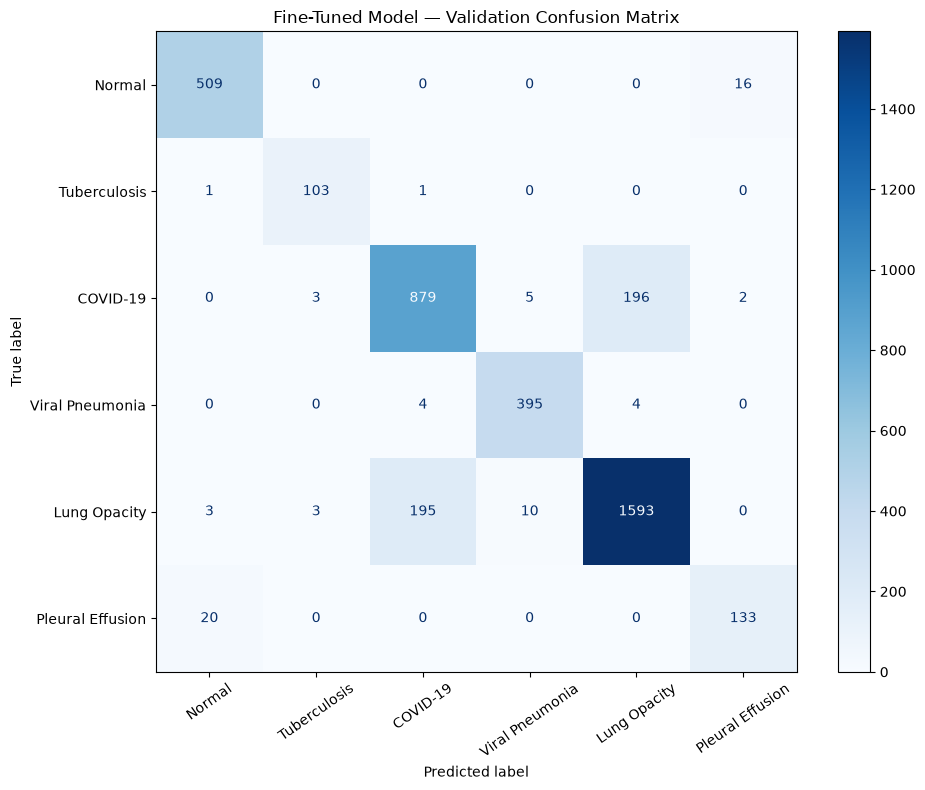


Most frequent validation errors:
true_class        predicted_class 
COVID-19          Lung Opacity        196
Lung Opacity      COVID-19            195
Pleural Effusion  Normal               20
Normal            Pleural Effusion     16
Lung Opacity      Viral Pneumonia      10
COVID-19          Viral Pneumonia       5
Viral Pneumonia   COVID-19              4
                  Lung Opacity          4
COVID-19          Tuberculosis          3
Lung Opacity      Normal                3
                  Tuberculosis          3
COVID-19          Pleural Effusion      2
Tuberculosis      Normal                1
                  COVID-19              1
dtype: int64

Total validation errors: 463
Validation accuracy: 0.8863803680981595


In [31]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

CLASS_NAMES = [
    "Normal",
    "Tuberculosis",
    "COVID-19",
    "Viral Pneumonia",
    "Lung Opacity",
    "Pleural Effusion",
]

# Use the saved fine-tuned model
y_val_true = []
y_val_pred = []
y_val_prob = []

for images, labels in val_ds:
    probabilities = fine_tuned_model(images, training=False).numpy()

    y_val_true.extend(labels.numpy().tolist())
    y_val_pred.extend(np.argmax(probabilities, axis=1).tolist())
    y_val_prob.extend(probabilities.tolist())

y_val_true = np.asarray(y_val_true)
y_val_pred = np.asarray(y_val_pred)
y_val_prob = np.asarray(y_val_prob)

# Validation confusion matrix
cm_val = confusion_matrix(
    y_val_true,
    y_val_pred,
    labels=list(range(6))
)

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_val,
    display_labels=CLASS_NAMES
)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=35, values_format="d")
ax.set_title("Fine-Tuned Model — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

# Identify the most frequent validation errors
errors = pd.DataFrame({
    "true_class": [CLASS_NAMES[i] for i in y_val_true],
    "predicted_class": [CLASS_NAMES[i] for i in y_val_pred],
})

errors = errors[errors["true_class"] != errors["predicted_class"]]

print("\nMost frequent validation errors:")
print(
    errors.groupby(["true_class", "predicted_class"])
    .size()
    .sort_values(ascending=False)
    .head(15)
)

print("\nTotal validation errors:", len(errors))
print("Validation accuracy:", np.mean(y_val_true == y_val_pred))


In [32]:

from pathlib import Path
import pandas as pd
import numpy as np

CLASS_NAMES = [
    "Normal",
    "Tuberculosis",
    "COVID-19",
    "Viral Pneumonia",
    "Lung Opacity",
    "Pleural Effusion",
]

# Predict on the validation set
val_true = []
val_pred = []
val_prob = []

for images, labels in val_ds:
    probabilities = fine_tuned_model(images, training=False).numpy()

    val_true.extend(labels.numpy().tolist())
    val_pred.extend(np.argmax(probabilities, axis=1).tolist())
    val_prob.extend(probabilities.tolist())

val_true = np.asarray(val_true)
val_pred = np.asarray(val_pred)
val_prob = np.asarray(val_prob)

# Align predictions with the saved validation CSV order.
# The dataset pipeline is not shuffled for validation.
assert len(val_true) == len(val_df)

audit_df = val_df.reset_index(drop=True).copy()
audit_df["true_label"] = val_true
audit_df["predicted_label"] = val_pred
audit_df["true_class"] = [
    CLASS_NAMES[i] for i in val_true
]
audit_df["predicted_class"] = [
    CLASS_NAMES[i] for i in val_pred
]
audit_df["confidence"] = np.max(val_prob, axis=1)
audit_df["correct"] = val_true == val_pred

# Focus on the two largest confusion directions
target_errors = audit_df[
    (
        (audit_df["true_class"] == "COVID-19") &
        (audit_df["predicted_class"] == "Lung Opacity")
    ) |
    (
        (audit_df["true_class"] == "Lung Opacity") &
        (audit_df["predicted_class"] == "COVID-19")
    )
].copy()

output_dir = Path.cwd() / "evaluation_results"
output_dir.mkdir(exist_ok=True)

target_errors.to_csv(
    output_dir / "covid_lung_opacity_errors.csv",
    index=False
)

print("COVID-19/Lung Opacity errors:", len(target_errors))
print("\nError directions:")
print(
    target_errors.groupby(
        ["true_class", "predicted_class"]
    ).size()
)
print("\nSaved:", output_dir / "covid_lung_opacity_errors.csv")
print("\nSample rows:")
print(
    target_errors[
        ["image_path", "true_class", "predicted_class", "confidence"]
    ].head(10).to_string(index=False)
)


COVID-19/Lung Opacity errors: 391

Error directions:
true_class    predicted_class
COVID-19      Lung Opacity       196
Lung Opacity  COVID-19           195
dtype: int64

Saved: c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\evaluation_results\covid_lung_opacity_errors.csv

Sample rows:
                                                                                                                               image_path   true_class predicted_class  confidence
C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\COVID-19_Radiography_Dataset\Lung_Opacity\images\Lung_Opacity-5579.png Lung Opacity        COVID-19    0.786303
               C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\COVID-19_Radiography_Dataset\COVID\masks\COVID-2477.png     COVID-19    Lung Opacity    0.675811
 C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\COVID-19_Radiography_Dataset\Lung_Opacity\masks\Lung_Opacity-4685.png Lung Opacity        COVID-

In [34]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd()
DATASETS_DIR = PROJECT_DIR / "Datasets"

CLASS_NAMES = [
    "Normal",
    "Tuberculosis",
    "COVID-19",
    "Viral Pneumonia",
    "Lung Opacity",
    "Pleural Effusion",
]

CLASS_TO_LABEL = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

records = []

# ---------------------------------------
# 1. TB dataset: original class folders
# ---------------------------------------
tb_dir = DATASETS_DIR / "TB_Chest_Radiography_Database"

for class_name in ["Normal", "Tuberculosis"]:
    class_dir = tb_dir / class_name

    for path in class_dir.iterdir():
        if path.is_file() and path.suffix.lower() in {".png", ".jpg", ".jpeg"}:
            records.append({
                "image_path": str(path.resolve()),
                "class_name": class_name,
                "label": CLASS_TO_LABEL[class_name],
                "source": "TB_Chest_Radiography_Database",
            })

# ---------------------------------------
# 2. COVID dataset: ONLY the images folders
# ---------------------------------------
covid_dir = DATASETS_DIR / "COVID-19_Radiography_Dataset"

source_folder_to_class = {
    "COVID": "COVID-19",
    "Viral Pneumonia": "Viral Pneumonia",
    "Lung_Opacity": "Lung Opacity",
    "Normal": "Normal",
}

for folder_name, class_name in source_folder_to_class.items():
    images_dir = covid_dir / folder_name / "images"

    if not images_dir.is_dir():
        raise FileNotFoundError(
            f"Expected original-image folder not found: {images_dir}"
        )

    for path in images_dir.iterdir():
        if path.is_file() and path.suffix.lower() in {".png", ".jpg", ".jpeg"}:
            records.append({
                "image_path": str(path.resolve()),
                "class_name": class_name,
                "label": CLASS_TO_LABEL[class_name],
                "source": "COVID-19_Radiography_Dataset",
            })

# ---------------------------------------
# 3. NIH Effusion: extracted original X-rays
# ---------------------------------------
effusion_dir = DATASETS_DIR / "NIH_ChestXray14" / "effusion_images"

if not effusion_dir.is_dir():
    raise FileNotFoundError(
        f"NIH Effusion image folder not found: {effusion_dir}"
    )

for path in effusion_dir.iterdir():
    if path.is_file() and path.suffix.lower() in {".png", ".jpg", ".jpeg"}:
        records.append({
            "image_path": str(path.resolve()),
            "class_name": "Pleural Effusion",
            "label": CLASS_TO_LABEL["Pleural Effusion"],
            "source": "NIH_ChestXray14",
        })

# ---------------------------------------
# 4. Validate and save new index
# ---------------------------------------
clean_index = pd.DataFrame(records)

if clean_index.empty:
    raise ValueError("No images were found. Check the dataset paths.")

clean_index = clean_index.drop_duplicates(subset=["image_path"])

if clean_index["image_path"].duplicated().any():
    raise ValueError("Duplicate image paths remain in the new index.")

# No path in this index should contain a masks directory.
mask_paths = clean_index["image_path"].str.contains(
    r"[\\/]masks[\\/]", case=False, regex=True
)

if mask_paths.any():
    raise ValueError("Mask images were found in the rebuilt index.")

new_index_path = DATASETS_DIR / "six_class_index_original_images.csv"
clean_index.to_csv(new_index_path, index=False)

print("New original-image index saved:", new_index_path)
print("\nClass counts:")
print(
    clean_index["class_name"]
    .value_counts()
    .reindex(CLASS_NAMES, fill_value=0)
    .to_string()
)

print("\nCounts by source and class:")
print(
    pd.crosstab(
        clean_index["source"],
        clean_index["class_name"]
    ).to_string()
)

print("\nTotal original images:", len(clean_index))
print("Mask images included:", int(mask_paths.sum()))
print("All indexed paths exist:",
      all(Path(p).is_file() for p in clean_index["image_path"]))


New original-image index saved: c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\six_class_index_original_images.csv

Class counts:
class_name
Normal              13692
Tuberculosis          700
COVID-19             3616
Viral Pneumonia      1345
Lung Opacity         6012
Pleural Effusion     1000

Counts by source and class:
class_name                     COVID-19  Lung Opacity  Normal  Pleural Effusion  Tuberculosis  Viral Pneumonia
source                                                                                                        
COVID-19_Radiography_Dataset       3616          6012   10192                 0             0             1345
NIH_ChestXray14                       0             0       0              1000             0                0
TB_Chest_Radiography_Database         0             0    3500                 0           700                0

Total original images: 26365
Mask images included: 0
All indexed paths exist: True


In [35]:

from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split

PROJECT_DIR = Path.cwd()
DATASETS_DIR = PROJECT_DIR / "Datasets"
NIH_DIR = DATASETS_DIR / "NIH_ChestXray14"

index_path = DATASETS_DIR / "six_class_index_original_images.csv"
metadata_path = NIH_DIR / "selected_effusion_metadata.csv"

df = pd.read_csv(index_path)
nih_metadata = pd.read_csv(metadata_path)

CLASS_NAMES = [
    "Normal",
    "Tuberculosis",
    "COVID-19",
    "Viral Pneumonia",
    "Lung Opacity",
    "Pleural Effusion",
]

# Attach patient IDs to NIH Effusion images
patient_lookup = (
    nih_metadata.drop_duplicates(subset="Image Index")
    .set_index("Image Index")["Patient ID"]
    .to_dict()
)

df["patient_id"] = ""

effusion_mask = df["class_name"].eq("Pleural Effusion")

df.loc[effusion_mask, "patient_id"] = (
    df.loc[effusion_mask, "image_path"]
    .apply(lambda p: patient_lookup.get(Path(p).name, ""))
    .astype(str)
)

effusion_df = df[effusion_mask].copy()
other_df = df[~effusion_mask].copy()

if effusion_df["patient_id"].eq("").any():
    raise ValueError("Some Effusion images have missing patient IDs.")

# Split NIH by patient
patients = effusion_df["patient_id"].unique().tolist()

train_patients, temp_patients = train_test_split(
    patients, test_size=0.30, random_state=42
)
val_patients, test_patients = train_test_split(
    temp_patients, test_size=0.50, random_state=42
)

nih_train = effusion_df[
    effusion_df["patient_id"].isin(train_patients)
].copy()

nih_val = effusion_df[
    effusion_df["patient_id"].isin(val_patients)
].copy()

nih_test = effusion_df[
    effusion_df["patient_id"].isin(test_patients)
].copy()

# Stratified splits for the other five classes
other_train, other_temp = train_test_split(
    other_df,
    test_size=0.30,
    stratify=other_df["label"],
    random_state=42
)

other_val, other_test = train_test_split(
    other_temp,
    test_size=0.50,
    stratify=other_temp["label"],
    random_state=42
)

train_df = pd.concat(
    [other_train, nih_train], ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

val_df = pd.concat(
    [other_val, nih_val], ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

test_df = pd.concat(
    [other_test, nih_test], ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

# Checks
assert len(train_df) + len(val_df) + len(test_df) == len(df)
assert set(train_df["image_path"]).isdisjoint(val_df["image_path"])
assert set(train_df["image_path"]).isdisjoint(test_df["image_path"])
assert set(val_df["image_path"]).isdisjoint(test_df["image_path"])

assert set(nih_train["patient_id"]).isdisjoint(nih_val["patient_id"])
assert set(nih_train["patient_id"]).isdisjoint(nih_test["patient_id"])
assert set(nih_val["patient_id"]).isdisjoint(nih_test["patient_id"])

# Save separate clean split files
train_df.to_csv(DATASETS_DIR / "train_split_clean.csv", index=False)
val_df.to_csv(DATASETS_DIR / "validation_split_clean.csv", index=False)
test_df.to_csv(DATASETS_DIR / "test_split_clean.csv", index=False)

print("CLEAN SPLIT SIZES")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(df))

for name, split in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{name} class counts:")
    print(
        split["class_name"]
        .value_counts()
        .reindex(CLASS_NAMES, fill_value=0)
        .to_string()
    )

print("\nNIH unique patients:")
print("Train:", len(set(nih_train["patient_id"])))
print("Validation:", len(set(nih_val["patient_id"])))
print("Test:", len(set(nih_test["patient_id"])))

print("\nClean split files saved successfully.")


CLEAN SPLIT SIZES
Train: 18459
Validation: 3958
Test: 3948
Total: 26365

Train class counts:
class_name
Normal              9584
Tuberculosis         490
COVID-19            2531
Viral Pneumonia      942
Lung Opacity        4208
Pleural Effusion     704

Validation class counts:
class_name
Normal              2054
Tuberculosis         105
COVID-19             542
Viral Pneumonia      202
Lung Opacity         902
Pleural Effusion     153

Test class counts:
class_name
Normal              2054
Tuberculosis         105
COVID-19             543
Viral Pneumonia      201
Lung Opacity         902
Pleural Effusion     143

NIH unique patients:
Train: 536
Validation: 115
Test: 115

Clean split files saved successfully.


In [36]:

from pathlib import Path
import pandas as pd
import tensorflow as tf

PROJECT_DIR = Path.cwd()
DATASETS_DIR = PROJECT_DIR / "Datasets"

IMG_SIZE = 224
BATCH_SIZE = 16
NUM_CLASSES = 6
AUTOTUNE = tf.data.AUTOTUNE

CLASS_NAMES = [
    "Normal",
    "Tuberculosis",
    "COVID-19",
    "Viral Pneumonia",
    "Lung Opacity",
    "Pleural Effusion",
]

# Load the new clean splits
train_df = pd.read_csv(DATASETS_DIR / "train_split_clean.csv")
val_df = pd.read_csv(DATASETS_DIR / "validation_split_clean.csv")
test_df = pd.read_csv(DATASETS_DIR / "test_split_clean.csv")

# Verify paths and labels
for split_name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    if not split_df["label"].between(0, NUM_CLASSES - 1).all():
        raise ValueError(f"Invalid label in {split_name}.")

    if not all(Path(p).is_file() for p in split_df["image_path"]):
        raise FileNotFoundError(
            f"Missing image path in {split_name}."
        )

    if split_df["image_path"].str.contains(
        r"[\\/]masks[\\/]", case=False, regex=True
    ).any():
        raise ValueError(f"Mask path found in {split_name}.")

print("Clean split sizes:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


def load_image(image_path, label):
    image_bytes = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)

    return image, tf.cast(label, tf.int32)


def make_dataset(split_df, training=False):
    paths = split_df["image_path"].astype(str).to_numpy()
    labels = split_df["label"].astype("int32").to_numpy()

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            min(len(split_df), 5000),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# Verify a batch
for images, labels in train_ds.take(1):
    print("\nImage batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel range:",
          float(tf.reduce_min(images)),
          "to",
          float(tf.reduce_max(images)))

    assert images.shape[1:] == (224, 224, 3)
    assert labels.shape[0] == images.shape[0]

print("\nClean TensorFlow datasets are ready.")


Clean split sizes:
Train: 18459
Validation: 3958
Test: 3948

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Pixel range: 0.0 to 254.4089813232422

Clean TensorFlow datasets are ready.


In [37]:

import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
from pathlib import Path

IMG_SIZE = 224
NUM_CLASSES = 6

CLASS_NAMES = [
    "Normal",
    "Tuberculosis",
    "COVID-19",
    "Viral Pneumonia",
    "Lung Opacity",
    "Pleural Effusion",
]

# ---------------------------------------
# 1. Transformer encoder
# ---------------------------------------
def transformer_encoder(
    x, num_heads=4, key_dim=64, mlp_dim=256, dropout=0.1
):
    attention = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=key_dim,
        dropout=dropout
    )(x, x)

    x = layers.Add()([x, attention])
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    ff = layers.Dense(mlp_dim, activation="gelu")(x)
    ff = layers.Dropout(dropout)(ff)
    ff = layers.Dense(256)(ff)

    x = layers.Add()([x, ff])
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    return x


# ---------------------------------------
# 2. Positional embedding
# ---------------------------------------
@tf.keras.utils.register_keras_serializable()
class AddPositionEmbedding(layers.Layer):
    def build(self, input_shape):
        self.num_tokens = input_shape[1]
        self.embedding_dim = input_shape[2]

        self.position_embeddings = self.add_weight(
            name="position_embeddings",
            shape=(self.num_tokens, self.embedding_dim),
            initializer="random_normal",
            trainable=True
        )

    def call(self, inputs):
        return inputs + tf.expand_dims(
            self.position_embeddings, axis=0
        )


# ---------------------------------------
# 3. Build the new hybrid model
# ---------------------------------------
inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="chest_xray_image"
)

preprocessed = tf.keras.applications.mobilenet_v2.preprocess_input(
    inputs
)

cnn_base = MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
cnn_base.trainable = False

feature_map = cnn_base(preprocessed, training=False)

tokens = layers.Reshape((-1, 1280), name="spatial_tokens")(
    feature_map
)
tokens = layers.Dense(256, name="token_projection")(tokens)
tokens = AddPositionEmbedding(name="position_embedding")(tokens)

tokens = transformer_encoder(tokens)

transformer_features = layers.GlobalAveragePooling1D()(tokens)
cnn_features = layers.GlobalAveragePooling2D()(feature_map)

combined = layers.Concatenate()([
    cnn_features,
    transformer_features
])
combined = layers.Dense(256, activation="relu")(combined)
combined = layers.BatchNormalization()(combined)
combined = layers.Dropout(0.4)(combined)
combined = layers.Dense(128, activation="relu")(combined)
combined = layers.Dropout(0.3)(combined)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    name="class_probabilities"
)(combined)

clean_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="clean_hybrid_cnn_transformer"
)

# ---------------------------------------
# 4. Calculate weights from clean labels
# ---------------------------------------
class_ids = np.arange(NUM_CLASSES)
clean_weights = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=train_df["label"].to_numpy(dtype=np.int32)
)

clean_class_weights = {
    int(i): float(w)
    for i, w in zip(class_ids, clean_weights)
}

print("Class weights:")
for i, weight in clean_class_weights.items():
    print(f"{CLASS_NAMES[i]}: {weight:.3f}")

# ---------------------------------------
# 5. Compile
# ---------------------------------------
clean_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

clean_model.summary()
print("\nOutput shape:", clean_model.output_shape)
print("Clean model compiled successfully.")


Class weights:
Normal: 0.321
Tuberculosis: 6.279
COVID-19: 1.216
Viral Pneumonia: 3.266
Lung Opacity: 0.731
Pleural Effusion: 4.370


Model: "clean_hybrid_cnn_transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ chest_xray_image    │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ true_divide_2       │ (None, 224, 224,  │          0 │ chest_xray_image… │
│ (TrueDivide)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subtract_2          │ (None, 224, 224,  │          0 │ true_divide_2[0]… │
│ (Subtract)          │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ subtract_2[0][0]  │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_tokens      │ (None, 49, 1280)  │          0 │ mobilenetv2_1.00… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_projection    │ (None, 49, 256)   │    327,936 │ spatial_tokens[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ position_embedding  │ (None, 49, 256)   │     12,544 │ token_projection… │
│ (AddPositionEmbedd… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 49, 256)   │    263,168 │ position_embeddi… │
│ (MultiHeadAttentio… │                   │            │ position_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 49, 256)   │          0 │ position_embeddi… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 49, 256)   │        512 │ add_5[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 49, 256)   │     65,792 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 49, 256)   │          0 │ dense_8[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 49, 256)   │     65,792 │ dropout_11[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 49, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 49, 256)   │        512 │ add_6[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 256)       │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 3,422,406 (13.06 MB)

 Trainable params: 1,163,910 (4.44 MB)

 Non-trainable params: 2,258,496 (8.62 MB)


Output shape: (None, 6)
Clean model compiled successfully.


In [38]:

for images, labels in train_ds.take(1):
    probabilities = clean_model(images, training=False)

    print("Input shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Prediction shape:", probabilities.shape)
    print(
        "All predictions finite:",
        bool(tf.reduce_all(tf.math.is_finite(probabilities)))
    )

    print("Example probabilities:", probabilities[0].numpy())
    print("Example predicted class:",
          CLASS_NAMES[int(tf.argmax(probabilities[0]).numpy())])

    assert probabilities.shape == (images.shape[0], 6)
    assert bool(tf.reduce_all(tf.math.is_finite(probabilities)))

print("\nClean model forward-pass test passed.")


Input shape: (16, 224, 224, 3)
Label shape: (16,)
Prediction shape: (16, 6)
All predictions finite: True
Example probabilities: [0.08587003 0.09084085 0.38019425 0.18296091 0.06670186 0.19343212]
Example predicted class: COVID-19

Clean model forward-pass test passed.


In [40]:

from pathlib import Path
import time
import tensorflow as tf

clean_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

clean_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(
        (Path.cwd() / "chest_xray_6class_clean_best.keras").resolve()
    ),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

clean_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
    verbose=1
)

clean_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

start_time = time.time()

clean_history = clean_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=clean_class_weights,
    callbacks=[
        clean_checkpoint,
        clean_early_stop,
        clean_reduce_lr
    ],
    verbose=1
)

print(
    f"\nTraining time: {(time.time() - start_time) / 60:.1f} minutes"
)
print("Best checkpoint: chest_xray_6class_clean_best.keras")


Epoch 1/10
1154/1154 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7029 - loss: 0.5387
Epoch 1: val_loss improved from None to 0.57654, saving model to C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\chest_xray_6class_clean_best.keras

Epoch 1: finished saving model to C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\chest_xray_6class_clean_best.keras
1154/1154 ━━━━━━━━━━━━━━━━━━━━ 1622s 1s/step - accuracy: 0.7234 - loss: 0.4932 - val_accuracy: 0.7898 - val_loss: 0.5765 - learning_rate: 1.0000e-04
Epoch 2/10
1154/1154 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7790 - loss: 0.3666
Epoch 2: val_loss did not improve from 0.57654
1154/1154 ━━━━━━━━━━━━━━━━━━━━ 1316s 1s/step - accuracy: 0.7897 - loss: 0.3490 - val_accuracy: 0.7751 - val_loss: 0.6111 - learning_rate: 1.0000e-04
Epoch 3/10
1154/1154 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step - accuracy: 0.8146 - loss: 0.3015
Epoch 3: val_loss did not improve from 0.57654

Epoch 3: ReduceLROnPlateau reducing learning rate to 1.99

In [27]:
from pathlib import Path

checkpoint = Path.cwd() / "chest_xray_6class_clean_best.keras"

print("Clean checkpoint exists:", checkpoint.is_file())
print("Checkpoint path:", checkpoint.resolve())

Clean checkpoint exists: True
Checkpoint path: C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\chest_xray_6class_clean_best.keras


In [30]:
import tensorflow as tf
import keras

@keras.saving.register_keras_serializable(package="Custom")
class AddPositionEmbedding(keras.layers.Layer):
    def build(self, input_shape):
        self.position_embeddings = self.add_weight(
            name="position_embeddings",
            shape=(1, input_shape[1], input_shape[2]),
            initializer="random_normal",
            trainable=True,
        )
        super().build(input_shape)

    def call(self, inputs):
        return inputs + self.position_embeddings

In [32]:
import zipfile
import json

checkpoint_path = "chest_xray_6class_clean_best.keras"

with zipfile.ZipFile(checkpoint_path, "r") as z:
    print("Checkpoint files:", z.namelist())

    config_file = next(
        name for name in z.namelist()
        if name.endswith("config.json")
    )

    config = json.loads(z.read(config_file))

    for layer in config["config"]["layers"]:
        if layer.get("class_name") == "AddPositionEmbedding":
            print(json.dumps(layer, indent=2))

Checkpoint files: ['metadata.json', 'config.json', 'model.weights.h5']
{
  "module": null,
  "class_name": "AddPositionEmbedding",
  "config": {
    "name": "position_embedding",
    "activity_regularizer": null,
    "trainable": true,
    "dtype": {
      "module": "keras",
      "class_name": "DTypePolicy",
      "config": {
        "name": "float32"
      },
      "registered_name": null,
      "shared_object_id": 1687721550688
    },
    "autocast": true
  },
  "registered_name": "Custom>AddPositionEmbedding",
  "build_config": {
    "input_shape": [
      null,
      49,
      256
    ]
  },
  "name": "position_embedding",
  "inbound_nodes": [
    {
      "args": [
        {
          "class_name": "__keras_tensor__",
          "config": {
            "shape": [
              null,
              49,
              256
            ],
            "dtype": "float32",
            "keras_history": [
              "token_projection",
              0,
              0
            ]
       

In [33]:
import h5py

checkpoint_path = "chest_xray_6class_clean_best.keras"

with zipfile.ZipFile(checkpoint_path, "r") as z:
    with z.open("model.weights.h5") as weights_file:
        with open("temp_model_weights.h5", "wb") as f:
            f.write(weights_file.read())

with h5py.File("temp_model_weights.h5", "r") as f:
    def inspect(name, obj):
        if "position_embedding" in name.lower():
            if isinstance(obj, h5py.Dataset):
                print(name, obj.shape)
            else:
                print(name)

    f.visititems(inspect)

layers/add_position_embedding
layers/add_position_embedding/vars
layers/add_position_embedding/vars/0 (49, 256)


In [34]:
import tensorflow as tf
import keras

@keras.saving.register_keras_serializable(package="Custom")
class AddPositionEmbedding(keras.layers.Layer):
    def build(self, input_shape):
        self.position_embeddings = self.add_weight(
            name="position_embeddings",
            shape=(input_shape[1], input_shape[2]),
            initializer="random_normal",
            trainable=True,
        )
        super().build(input_shape)

    def call(self, inputs):
        return inputs + self.position_embeddings

In [35]:
clean_model = keras.models.load_model(
    "chest_xray_6class_clean_best.keras",
    compile=False
)

print("Clean model loaded successfully!")
clean_model.summary()

Clean model loaded successfully!


Model: "clean_hybrid_cnn_transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ chest_xray_image    │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ true_divide_2       │ (None, 224, 224,  │          0 │ chest_xray_image… │
│ (TrueDivide)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subtract_2          │ (None, 224, 224,  │          0 │ true_divide_2[0]… │
│ (Subtract)          │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ subtract_2[0][0]  │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_tokens      │ (None, 49, 1280)  │          0 │ mobilenetv2_1.00… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_projection    │ (None, 49, 256)   │    327,936 │ spatial_tokens[0… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ position_embedding  │ (None, 49, 256)   │     12,544 │ token_projection… │
│ (AddPositionEmbedd… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 49, 256)   │    263,168 │ position_embeddi… │
│ (MultiHeadAttentio… │                   │            │ position_embeddi… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_5 (Add)         │ (None, 49, 256)   │          0 │ position_embeddi… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 49, 256)   │        512 │ add_5[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 49, 256)   │     65,792 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 49, 256)   │          0 │ dense_8[0][0]     │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 49, 256)   │     65,792 │ dropout_11[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (None, 49, 256)   │          0 │ layer_normalizat… │
│                     │                   │            │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 49, 256)   │        512 │ add_6[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 256)       │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 3,422,406 (13.06 MB)

 Trainable params: 1,163,910 (4.44 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

In [39]:
from pathlib import Path
import pandas as pd

project_dir = Path.cwd()
test_csv = project_dir / "Datasets" / "test_split_clean.csv"

test_df = pd.read_csv(test_csv)

print("Test samples:", len(test_df))
print("\nSamples per class:")
print(test_df["class_name"].value_counts().sort_index())

print("\nFirst 5 test rows:")
print(test_df.head().to_string(index=False))

# Check whether image paths exist
test_df["exists"] = test_df["image_path"].apply(
    lambda p: Path(p).is_file()
)

print("\nExisting image files:", test_df["exists"].sum())
print("Missing image files:", (~test_df["exists"]).sum())

Test samples: 3948

Samples per class:
class_name
COVID-19             543
Lung Opacity         902
Normal              2054
Pleural Effusion     143
Tuberculosis         105
Viral Pneumonia      201
Name: count, dtype: int64

First 5 test rows:
                                                                                                                               image_path   class_name  label                       source  patient_id
            C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\COVID-19_Radiography_Dataset\Normal\images\Normal-4291.png       Normal      0 COVID-19_Radiography_Dataset         NaN
            C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\COVID-19_Radiography_Dataset\Normal\images\Normal-6964.png       Normal      0 COVID-19_Radiography_Dataset         NaN
            C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\COVID-19_Radiography_Dataset\Normal\images\Normal-6175.png       Normal      0

In [40]:
import tensorflow as tf
import pandas as pd
from pathlib import Path

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

project_dir = Path.cwd()
test_df = pd.read_csv(
    project_dir / "Datasets" / "test_split_clean.csv"
)

def load_test_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.int32)

test_ds = tf.data.Dataset.from_tensor_slices((
    test_df["image_path"].astype(str).values,
    test_df["label"].astype("int32").values
))

test_ds = (
    test_ds
    .map(load_test_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())
print("Test samples:", len(test_df))

Test batches: 247
Test samples: 3948


In [41]:
test_loss, test_accuracy = clean_model.evaluate(
    test_ds,
    verbose=1
)

print(f"\nTest loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

247/247 ━━━━━━━━━━━━━━━━━━━━ 41s 160ms/step - accuracy: 0.8908 - loss: 0.3202

Test loss: 0.3202
Test accuracy: 89.08%


In [42]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = clean_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

class_names = [
    "Normal",
    "Tuberculosis",
    "COVID-19",
    "Viral Pneumonia",
    "Lung Opacity",
    "Pleural Effusion"
]

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(6)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=list(range(6))))

247/247 ━━━━━━━━━━━━━━━━━━━━ 42s 168ms/step
                  precision    recall  f1-score   support

          Normal     0.9414    0.8759    0.9074      2054
    Tuberculosis     0.8898    1.0000    0.9417       105
        COVID-19     0.8616    0.9061    0.8833       543
 Viral Pneumonia     0.8383    0.9801    0.9037       201
    Lung Opacity     0.8522    0.8825    0.8671       902
Pleural Effusion     0.7151    0.8951    0.7950       143

        accuracy                         0.8908      3948
       macro avg     0.8497    0.9233    0.8830      3948
    weighted avg     0.8952    0.8908    0.8916      3948

Confusion matrix:
[[1799    4   51   35  116   49]
 [   0  105    0    0    0    0]
 [  18    9  492    2   21    1]
 [   4    0    0  197    0    0]
 [  76    0   28    1  796    1]
 [  14    0    0    0    1  128]]


In [43]:
print(
    test_df[["class_name", "label"]]
    .drop_duplicates()
    .sort_values("label")
    .to_string(index=False)
)

      class_name  label
          Normal      0
    Tuberculosis      1
        COVID-19      2
 Viral Pneumonia      3
    Lung Opacity      4
Pleural Effusion      5


In [1]:
from pathlib import Path

project_dir = Path.cwd()
datasets_dir = project_dir / "Datasets"

for filename in [
    "train_split_clean.csv",
    "validation_split_clean.csv",
    "test_split_clean.csv",
]:
    path = datasets_dir / filename
    print(f"{filename}: {'Found' if path.exists() else 'Missing'}")

train_split_clean.csv: Found
validation_split_clean.csv: Found
test_split_clean.csv: Found


In [2]:
from pathlib import Path
import pandas as pd

project_dir = Path.cwd()
datasets_dir = project_dir / "Datasets"

selected_classes = ["Normal", "Tuberculosis", "COVID-19"]

split_files = {
    "train": "train_split_clean.csv",
    "validation": "validation_split_clean.csv",
    "test": "test_split_clean.csv",
}

for split_name, filename in split_files.items():
    df = pd.read_csv(datasets_dir / filename)

    three_class_df = df[
        df["class_name"].isin(selected_classes)
    ].copy()

    # Preserve the original labels: Normal=0, TB=1, COVID-19=2
    output_path = datasets_dir / f"{split_name}_3class.csv"
    three_class_df.to_csv(output_path, index=False)

    print(f"\n{split_name.title()}: {len(three_class_df)} images")
    print(three_class_df["class_name"].value_counts().to_string())
    print("Saved:", output_path.name)


Train: 12605 images
class_name
Normal          9584
COVID-19        2531
Tuberculosis     490
Saved: train_3class.csv

Validation: 2701 images
class_name
Normal          2054
COVID-19         542
Tuberculosis     105
Saved: validation_3class.csv

Test: 2702 images
class_name
Normal          2054
COVID-19         543
Tuberculosis     105
Saved: test_3class.csv


In [3]:
import tensorflow as tf
import pandas as pd
from pathlib import Path

project_dir = Path.cwd()
datasets_dir = project_dir / "Datasets"

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.int32)

def create_dataset(csv_name, shuffle=False):
    df = pd.read_csv(datasets_dir / csv_name)

    ds = tf.data.Dataset.from_tensor_slices((
        df["image_path"].astype(str).values,
        df["label"].astype("int32").values
    ))

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        ds = ds.shuffle(
            buffer_size=min(len(df), 2000),
            seed=42,
            reshuffle_each_iteration=True
        )

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_3class_ds = create_dataset("train_3class.csv", shuffle=True)
val_3class_ds = create_dataset("validation_3class.csv")
test_3class_ds = create_dataset("test_3class.csv")

print("Three-class datasets created successfully.")
print("Train batches:", tf.data.experimental.cardinality(train_3class_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_3class_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_3class_ds).numpy())

Three-class datasets created successfully.
Train batches: 788
Validation batches: 169
Test batches: 169


In [6]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from sklearn.utils.class_weight import compute_class_weight
import pandas as pd
import numpy as np
from pathlib import Path

IMG_SIZE = 224
NUM_CLASSES_3 = 3

CLASS_NAMES_3 = ["Normal", "Tuberculosis", "COVID-19"]

project_dir = Path.cwd()
train_3class_df = pd.read_csv(
    project_dir / "Datasets" / "train_3class.csv"
)

def transformer_encoder_3(x, num_heads=4, key_dim=64,
                          mlp_dim=256, dropout=0.1):
    attention = layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=key_dim,
        dropout=dropout
    )(x, x)

    x = layers.Add()([x, attention])
    x = layers.LayerNormalization(epsilon=1e-6)(x)

    ff = layers.Dense(mlp_dim, activation="gelu")(x)
    ff = layers.Dropout(dropout)(ff)
    ff = layers.Dense(256)(ff)

    x = layers.Add()([x, ff])
    return layers.LayerNormalization(epsilon=1e-6)(x)


@tf.keras.utils.register_keras_serializable(package="ThreeClass")
class AddPositionEmbedding3(layers.Layer):
    def build(self, input_shape):
        self.position_embeddings = self.add_weight(
            name="position_embeddings",
            shape=(input_shape[1], input_shape[2]),
            initializer="random_normal",
            trainable=True
        )
        super().build(input_shape)

    def call(self, inputs):
        return inputs + tf.expand_dims(
            self.position_embeddings, axis=0
        )


inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="chest_xray_image"
)

preprocessed = tf.keras.applications.mobilenet_v2.preprocess_input(
    inputs
)

cnn_base = MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)
cnn_base.trainable = False

feature_map = cnn_base(preprocessed, training=False)

tokens = layers.Reshape((-1, 1280))(feature_map)
tokens = layers.Dense(256, name="token_projection")(tokens)
tokens = AddPositionEmbedding3(name="position_embedding")(tokens)
tokens = transformer_encoder_3(tokens)

transformer_features = layers.GlobalAveragePooling1D()(tokens)
cnn_features = layers.GlobalAveragePooling2D()(feature_map)

combined = layers.Concatenate()([
    cnn_features, transformer_features
])
combined = layers.Dense(256, activation="relu")(combined)
combined = layers.BatchNormalization()(combined)
combined = layers.Dropout(0.4)(combined)
combined = layers.Dense(128, activation="relu")(combined)
combined = layers.Dropout(0.3)(combined)

outputs = layers.Dense(
    NUM_CLASSES_3,
    activation="softmax",
    name="class_probabilities"
)(combined)

model_3class = Model(
    inputs, outputs, name="hybrid_cnn_transformer_3class"
)

class_ids = np.arange(NUM_CLASSES_3)
weights = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=train_3class_df["label"].to_numpy(dtype=np.int32)
)
class_weights_3 = {
    int(i): float(w) for i, w in zip(class_ids, weights)
}

model_3class.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Class weights:", {
    CLASS_NAMES_3[i]: round(class_weights_3[i], 3)
    for i in class_ids
})
print("Input shape:", model_3class.input_shape)
print("Output shape:", model_3class.output_shape)
print("Three-class model built successfully.")


Class weights: {'Normal': 0.438, 'Tuberculosis': 8.575, 'COVID-19': 1.66}
Input shape: (None, 224, 224, 3)
Output shape: (None, 3)
Three-class model built successfully.


In [7]:
from pathlib import Path
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

checkpoint_3class = (
    Path.cwd() / "chest_xray_3class_best.keras"
)

callbacks_3class = [
    ModelCheckpoint(
        filepath=str(checkpoint_3class),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )
]

history_3class = model_3class.fit(
    train_3class_ds,
    validation_data=val_3class_ds,
    epochs=15,
    class_weight=class_weights_3,
    callbacks=callbacks_3class,
    verbose=1
)

print("Best three-class checkpoint:", checkpoint_3class)

Epoch 1/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 0s 554ms/step - accuracy: 0.5632 - loss: 0.8915
Epoch 1: val_loss improved from None to 0.46955, saving model to c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\chest_xray_3class_best.keras

Epoch 1: finished saving model to c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\chest_xray_3class_best.keras
788/788 ━━━━━━━━━━━━━━━━━━━━ 521s 630ms/step - accuracy: 0.6817 - loss: 0.6360 - val_accuracy: 0.8134 - val_loss: 0.4696
Epoch 2/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8324 - loss: 0.3497
Epoch 2: val_loss improved from 0.46955 to 0.37618, saving model to c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\chest_xray_3class_best.keras

Epoch 2: finished saving model to c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\chest_xray_3class_best.keras
788/788 ━━━━━━━━━━━━━━━━━━━━ 921s 1s/step - accuracy: 0.8511 - loss: 0.3190 - val_accuracy: 0.8608 - val_loss: 0.3762
Epoch 3/15
788/788 ━━━━━━━━━━━━━━━━━━

In [8]:

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Evaluate the trained 3-class model on the held-out test set
test_loss_3, test_accuracy_3 = model_3class.evaluate(
    test_3class_ds,
    verbose=1
)

print(f"\n3-class test loss: {test_loss_3:.4f}")
print(f"3-class test accuracy: {test_accuracy_3:.4%}")

# Generate predictions
y_true_3 = np.concatenate([
    labels.numpy() for _, labels in test_3class_ds
])

y_prob_3 = model_3class.predict(test_3class_ds, verbose=1)
y_pred_3 = np.argmax(y_prob_3, axis=1)

# Report per-class precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(
    y_true_3,
    y_pred_3,
    labels=[0, 1, 2],
    target_names=["Normal", "Tuberculosis", "COVID-19"],
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_true_3, y_pred_3, labels=[0, 1, 2]))


169/169 ━━━━━━━━━━━━━━━━━━━━ 53s 317ms/step - accuracy: 0.9652 - loss: 0.1008

3-class test loss: 0.1008
3-class test accuracy: 96.5211%
169/169 ━━━━━━━━━━━━━━━━━━━━ 32s 184ms/step

Classification Report:
              precision    recall  f1-score   support

      Normal     0.9776    0.9791    0.9784      2054
Tuberculosis     0.9352    0.9619    0.9484       105
    COVID-19     0.9236    0.9134    0.9185       543

    accuracy                         0.9652      2702
   macro avg     0.9455    0.9515    0.9484      2702
weighted avg     0.9651    0.9652    0.9652      2702

Confusion Matrix:
[[2011    3   40]
 [   3  101    1]
 [  43    4  496]]


In [1]:

from pathlib import Path
import shutil

# Project folder
PROJECT_DIR = Path.cwd()

# Existing best 3-class model
MODEL_PATH = PROJECT_DIR / "chest_xray_3class_best.keras"

# Separate backup folder
BACKUP_DIR = PROJECT_DIR / "model_backups"
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

BACKUP_PATH = BACKUP_DIR / "chest_xray_3class_best_original.keras"

if not MODEL_PATH.exists():
    print("Model not found at:", MODEL_PATH)
    print("Check that your notebook is running from the project folder.")
else:
    shutil.copy2(MODEL_PATH, BACKUP_PATH)
    print("Backup created successfully!")
    print("Original model:", MODEL_PATH)
    print("Backup model:", BACKUP_PATH)
    print("Backup size:", round(BACKUP_PATH.stat().st_size / (1024**2), 2), "MB")


Backup created successfully!
Original model: c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\chest_xray_3class_best.keras
Backup model: c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\model_backups\chest_xray_3class_best_original.keras
Backup size: 22.58 MB


In [2]:

from pathlib import Path
import pandas as pd
import tensorflow as tf
import numpy as np

# Project paths
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "Datasets"
BACKUP_PATH = (
    PROJECT_DIR
    / "model_backups"
    / "chest_xray_3class_best_original.keras"
)

# Confirm our files exist before proceeding
required_files = [
    BACKUP_PATH,
    DATA_DIR / "train_3class.csv",
    DATA_DIR / "validation_3class.csv",
]

for path in required_files:
    print(f"{'FOUND' if path.exists() else 'MISSING'}: {path}")

# Read split metadata
train_tuning_df = pd.read_csv(DATA_DIR / "train_3class.csv")
val_tuning_df = pd.read_csv(DATA_DIR / "validation_3class.csv")

print("\nTraining samples:", len(train_tuning_df))
print("Validation samples:", len(val_tuning_df))

print("\nTraining class counts:")
print(train_tuning_df["class_name"].value_counts())

print("\nValidation class counts:")
print(val_tuning_df["class_name"].value_counts())

# Keep the original checkpoint untouched
TUNING_DIR = PROJECT_DIR / "hyperparameter_tuning"
TUNING_DIR.mkdir(parents=True, exist_ok=True)

print("\nTuning output directory:", TUNING_DIR)


FOUND: c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\model_backups\chest_xray_3class_best_original.keras
FOUND: c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\train_3class.csv
FOUND: c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\validation_3class.csv

Training samples: 12605
Validation samples: 2701

Training class counts:
class_name
Normal          9584
COVID-19        2531
Tuberculosis     490
Name: count, dtype: int64

Validation class counts:
class_name
Normal          2054
COVID-19         542
Tuberculosis     105
Name: count, dtype: int64

Tuning output directory: c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\hyperparameter_tuning


In [4]:

import tensorflow as tf
from tensorflow.keras import layers

@tf.keras.utils.register_keras_serializable(package="ThreeClass")
class AddPositionEmbedding3(layers.Layer):
    def build(self, input_shape):
        self.num_tokens = input_shape[1]
        self.embedding_dim = input_shape[2]

        self.position_embeddings = self.add_weight(
            name="position_embeddings",
            shape=(self.num_tokens, self.embedding_dim),
            initializer="random_normal",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):
        return inputs + tf.expand_dims(
            self.position_embeddings, axis=0
        )

print("Custom layer registered successfully.")


Custom layer registered successfully.


In [5]:

from pathlib import Path
import tensorflow as tf

BACKUP_PATH = (
    Path.cwd()
    / "model_backups"
    / "chest_xray_3class_best_original.keras"
)

tuning_base_model = tf.keras.models.load_model(
    BACKUP_PATH,
    custom_objects={
        "AddPositionEmbedding3": AddPositionEmbedding3,
        "ThreeClass>AddPositionEmbedding3": AddPositionEmbedding3,
    },
    compile=False
)

print("Model loaded successfully!")
print("Model name:", tuning_base_model.name)
print("Input shape:", tuning_base_model.input_shape)
print("Output shape:", tuning_base_model.output_shape)
print("Total parameters:", tuning_base_model.count_params())



Model loaded successfully!
Model name: hybrid_cnn_transformer_3class
Input shape: (None, 224, 224, 3)
Output shape: (None, 3)
Total parameters: 3422019


In [6]:

print("Layer trainability summary")
print("-" * 75)

for i, layer in enumerate(tuning_base_model.layers):
    print(
        f"{i:02d} | {layer.name:35s} | "
        f"{layer.__class__.__name__:25s} | "
        f"Trainable: {layer.trainable}"
    )

trainable_params = sum(
    tf.keras.backend.count_params(w)
    for w in tuning_base_model.trainable_weights
)

non_trainable_params = sum(
    tf.keras.backend.count_params(w)
    for w in tuning_base_model.non_trainable_weights
)

print("\nTotal parameters:", tuning_base_model.count_params())
print("Trainable parameters:", trainable_params)
print("Non-trainable parameters:", non_trainable_params)


Layer trainability summary
---------------------------------------------------------------------------
00 | chest_xray_image                    | InputLayer                | Trainable: True
01 | mobilenetv2_1.00_224                | Functional                | Trainable: False
02 | reshape                             | Reshape                   | Trainable: True
03 | token_projection                    | Dense                     | Trainable: True
04 | position_embedding                  | AddPositionEmbedding3     | Trainable: True
05 | multi_head_attention                | MultiHeadAttention        | Trainable: True
06 | add                                 | Add                       | Trainable: True
07 | layer_normalization                 | LayerNormalization        | Trainable: True
08 | dense                               | Dense                     | Trainable: True
09 | dropout_1                           | Dropout                   | Trainable: True
10 | dense_1              

In [7]:

import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "Datasets"
TUNING_DIR = PROJECT_DIR / "hyperparameter_tuning"

train_tuning_df = pd.read_csv(DATA_DIR / "train_3class.csv")
val_tuning_df = pd.read_csv(DATA_DIR / "validation_3class.csv")

NUM_CLASSES_3 = 3
CLASS_NAMES_3 = ["Normal", "Tuberculosis", "COVID-19"]

class_ids_3 = np.array([0, 1, 2])

weights_array_3 = compute_class_weight(
    class_weight="balanced",
    classes=class_ids_3,
    y=train_tuning_df["label"].to_numpy(dtype=np.int32)
)

class_weights_tuning = {
    int(class_id): float(weight)
    for class_id, weight in zip(class_ids_3, weights_array_3)
}

print("Learning-rate candidates:", [1e-4, 3e-5])
print("Training samples:", len(train_tuning_df))
print("Validation samples:", len(val_tuning_df))
print("Class weights:", class_weights_tuning)

assert tuning_base_model.output_shape[-1] == 3
assert len(train_tuning_df) > 0 and len(val_tuning_df) > 0

print("\nSetup checks passed.")
print("Original checkpoint remains unchanged.")


Learning-rate candidates: [0.0001, 3e-05]
Training samples: 12605
Validation samples: 2701
Class weights: {0: 0.43840428491930994, 1: 8.57482993197279, 2: 1.6600816541551429}

Setup checks passed.
Original checkpoint remains unchanged.


In [9]:

import pandas as pd
import tensorflow as tf
from pathlib import Path

# Dataset settings
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "Datasets"

IMG_SIZE = (224, 224)
BATCH_SIZE = 16

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, tf.cast(label, tf.int32)

def create_dataset(csv_name, shuffle=False):
    df = pd.read_csv(DATA_DIR / csv_name)

    ds = tf.data.Dataset.from_tensor_slices((
        df["image_path"].astype(str).values,
        df["label"].astype("int32").values
    ))

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        ds = ds.shuffle(
            buffer_size=min(len(df), 2000),
            seed=42,
            reshuffle_each_iteration=True
        )

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_3class_ds = create_dataset(
    "train_3class.csv",
    shuffle=True
)

val_3class_ds = create_dataset(
    "validation_3class.csv"
)

print("Training dataset batches:", len(train_3class_ds))
print("Validation dataset batches:", len(val_3class_ds))
print("Datasets recreated successfully.")


Training dataset batches: 788
Validation dataset batches: 169
Datasets recreated successfully.


In [10]:

import gc
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Confirm the data pipelines from the earlier training step exist.
for name in ["train_3class_ds", "val_3class_ds"]:
    if name not in globals():
        raise NameError(
            f"{name} is missing. Re-run the cell that creates the "
            "three-class TensorFlow datasets before continuing."
        )

TUNING_DIR = Path.cwd() / "hyperparameter_tuning"
TUNING_DIR.mkdir(parents=True, exist_ok=True)

BACKUP_PATH = (
    Path.cwd()
    / "model_backups"
    / "chest_xray_3class_best_original.keras"
)

learning_rates = [1e-4, 3e-5]
trial_results = []

# Snapshot the exact same starting weights for both trials.
initial_weights = tuning_base_model.get_weights()

for lr in learning_rates:
    print(f"\n{'=' * 60}")
    print(f"Starting learning-rate trial: {lr}")
    print(f"{'=' * 60}")

    tf.keras.backend.clear_session()
    gc.collect()

    # Rebuild from the saved architecture and reset to the same weights.
    trial_model = tf.keras.models.load_model(
        BACKUP_PATH,
        custom_objects={
            "AddPositionEmbedding3": AddPositionEmbedding3,
            "ThreeClass>AddPositionEmbedding3": AddPositionEmbedding3,
        },
        compile=False
    )

    trial_model.set_weights(initial_weights)

    # Keep the CNN backbone frozen.
    trial_model.get_layer("mobilenetv2_1.00_224").trainable = False

    trial_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    trial_path = TUNING_DIR / f"lr_{lr:.0e}_best.keras"

    callbacks = [
        ModelCheckpoint(
            filepath=str(trial_path),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
            verbose=1
        ),
        EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=2,
            restore_best_weights=True,
            verbose=1
        )
    ]

    history = trial_model.fit(
        train_3class_ds,
        validation_data=val_3class_ds,
        epochs=6,
        class_weight=class_weights_tuning,
        callbacks=callbacks,
        verbose=1
    )

    best_epoch_idx = int(np.argmin(history.history["val_loss"]))

    trial_results.append({
        "learning_rate": lr,
        "best_epoch": best_epoch_idx + 1,
        "best_val_loss": float(history.history["val_loss"][best_epoch_idx]),
        "val_accuracy_at_best_loss": float(
            history.history["val_accuracy"][best_epoch_idx]
        ),
        "checkpoint": str(trial_path)
    })

    print("Best validation loss:", trial_results[-1]["best_val_loss"])
    print("Saved checkpoint:", trial_path)

    del trial_model, history
    gc.collect()

results_df = pd.DataFrame(trial_results)
results_path = TUNING_DIR / "learning_rate_results.csv"
results_df.to_csv(results_path, index=False)

print("\nLEARNING-RATE COMPARISON")
print(results_df.to_string(index=False))
print("\nResults saved to:", results_path)



Starting learning-rate trial: 0.0001
Epoch 1/6
788/788 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9280 - loss: 0.1663
Epoch 1: val_loss improved from None to 0.09233, saving model to c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\hyperparameter_tuning\lr_1e-04_best.keras

Epoch 1: finished saving model to c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\hyperparameter_tuning\lr_1e-04_best.keras
788/788 ━━━━━━━━━━━━━━━━━━━━ 1203s 2s/step - accuracy: 0.9323 - loss: 0.1515 - val_accuracy: 0.9719 - val_loss: 0.0923
Epoch 2/6
788/788 ━━━━━━━━━━━━━━━━━━━━ 0s 631ms/step - accuracy: 0.9493 - loss: 0.1137
Epoch 2: val_loss did not improve from 0.09233
788/788 ━━━━━━━━━━━━━━━━━━━━ 586s 704ms/step - accuracy: 0.9506 - loss: 0.1033 - val_accuracy: 0.9600 - val_loss: 0.1181
Epoch 3/6
788/788 ━━━━━━━━━━━━━━━━━━━━ 0s 251ms/step - accuracy: 0.9567 - loss: 0.0865
Epoch 3: val_loss did not improve from 0.09233
788/788 ━━━━━━━━━━━━━━━━━━━━ 229s 288ms/step - accuracy: 0.9598 - loss

In [11]:

import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix

TUNING_DIR = Path.cwd() / "hyperparameter_tuning"

best_lr_path = TUNING_DIR / "lr_3e-05_best.keras"

if not best_lr_path.exists():
    raise FileNotFoundError(f"Checkpoint not found: {best_lr_path}")

best_lr_model = tf.keras.models.load_model(
    best_lr_path,
    custom_objects={
        "AddPositionEmbedding3": AddPositionEmbedding3,
        "ThreeClass>AddPositionEmbedding3": AddPositionEmbedding3,
    },
    compile=False
)

best_lr_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

val_loss, val_accuracy = best_lr_model.evaluate(
    val_3class_ds,
    verbose=1
)

y_val_true = np.concatenate([
    labels.numpy() for _, labels in val_3class_ds
])

y_val_prob = best_lr_model.predict(
    val_3class_ds,
    verbose=1
)

y_val_pred = np.argmax(y_val_prob, axis=1)

print(f"\nValidation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy:.4%}")

print("\nValidation classification report:")
print(classification_report(
    y_val_true,
    y_val_pred,
    labels=[0, 1, 2],
    target_names=["Normal", "Tuberculosis", "COVID-19"],
    digits=4,
    zero_division=0
))

print("Validation confusion matrix:")
print(confusion_matrix(
    y_val_true,
    y_val_pred,
    labels=[0, 1, 2]
))


169/169 ━━━━━━━━━━━━━━━━━━━━ 29s 164ms/step - accuracy: 0.9733 - loss: 0.0830
169/169 ━━━━━━━━━━━━━━━━━━━━ 32s 186ms/step

Validation loss: 0.0830
Validation accuracy: 97.3343%

Validation classification report:
              precision    recall  f1-score   support

      Normal     0.9892    0.9786    0.9838      2054
Tuberculosis     0.9352    0.9619    0.9484       105
    COVID-19     0.9234    0.9557    0.9393       542

    accuracy                         0.9733      2701
   macro avg     0.9492    0.9654    0.9572      2701
weighted avg     0.9739    0.9733    0.9735      2701

Validation confusion matrix:
[[2010    5   39]
 [   0  101    4]
 [  22    2  518]]


In [12]:

import gc
import numpy as np
import tensorflow as tf
from pathlib import Path
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

TUNING_DIR = Path.cwd() / "hyperparameter_tuning"
BACKUP_PATH = (
    Path.cwd()
    / "model_backups"
    / "chest_xray_3class_best_original.keras"
)

lr = 1e-5
trial_path = TUNING_DIR / "lr_1e-05_best.keras"

# Load the same starting checkpoint used for previous trials
tf.keras.backend.clear_session()
gc.collect()

trial_model_1e5 = tf.keras.models.load_model(
    BACKUP_PATH,
    custom_objects={
        "AddPositionEmbedding3": AddPositionEmbedding3,
        "ThreeClass>AddPositionEmbedding3": AddPositionEmbedding3,
    },
    compile=False
)

# Freeze the CNN backbone
trial_model_1e5.get_layer("mobilenetv2_1.00_224").trainable = False

trial_model_1e5.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_1e5 = [
    ModelCheckpoint(
        filepath=str(trial_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=2,
        restore_best_weights=True,
        verbose=1
    )
]

history_1e5 = trial_model_1e5.fit(
    train_3class_ds,
    validation_data=val_3class_ds,
    epochs=6,
    class_weight=class_weights_tuning,
    callbacks=callbacks_1e5,
    verbose=1
)

best_idx = int(np.argmin(history_1e5.history["val_loss"]))

print("\nLearning rate:", lr)
print("Best epoch:", best_idx + 1)
print("Best validation loss:",
      round(history_1e5.history["val_loss"][best_idx], 5))
print("Validation accuracy at best loss:",
      round(history_1e5.history["val_accuracy"][best_idx] * 100, 2), "%")
print("Checkpoint:", trial_path)


Epoch 1/6
788/788 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step - accuracy: 0.9363 - loss: 0.1375
Epoch 1: val_loss improved from None to 0.11021, saving model to c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\hyperparameter_tuning\lr_1e-05_best.keras

Epoch 1: finished saving model to c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\hyperparameter_tuning\lr_1e-05_best.keras
788/788 ━━━━━━━━━━━━━━━━━━━━ 399s 493ms/step - accuracy: 0.9376 - loss: 0.1285 - val_accuracy: 0.9648 - val_loss: 0.1102
Epoch 2/6
788/788 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step - accuracy: 0.9417 - loss: 0.1275
Epoch 2: val_loss did not improve from 0.11021
788/788 ━━━━━━━━━━━━━━━━━━━━ 388s 490ms/step - accuracy: 0.9415 - loss: 0.1191 - val_accuracy: 0.9630 - val_loss: 0.1170
Epoch 3/6
788/788 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - accuracy: 0.9469 - loss: 0.1103
Epoch 3: val_loss improved from 0.11021 to 0.09766, saving model to c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\hyperparameter_tuning\lr

In [1]:

import pandas as pd
from pathlib import Path

TUNING_DIR = Path.cwd() / "hyperparameter_tuning"

lr_summary = pd.DataFrame([
    {
        "learning_rate": 1e-4,
        "best_epoch": 1,
        "best_val_loss": 0.0923263356,
        "val_accuracy_at_best_loss": 0.971862,
        "checkpoint": "lr_1e-04_best.keras"
    },
    {
        "learning_rate": 3e-5,
        "best_epoch": 3,
        "best_val_loss": 0.083002,
        "val_accuracy_at_best_loss": 0.973343,
        "checkpoint": "lr_3e-05_best.keras"
    },
    {
        "learning_rate": 1e-5,
        "best_epoch": 5,
        "best_val_loss": 0.09356,
        "val_accuracy_at_best_loss": 0.9689,
        "checkpoint": "lr_1e-05_best.keras"
    }
])

summary_path = TUNING_DIR / "learning_rate_comparison.csv"
lr_summary.to_csv(summary_path, index=False)

print(lr_summary.to_string(index=False))
print("\nSummary saved to:", summary_path)


 learning_rate  best_epoch  best_val_loss  val_accuracy_at_best_loss          checkpoint
       0.00010           1       0.092326                   0.971862 lr_1e-04_best.keras
       0.00003           3       0.083002                   0.973343 lr_3e-05_best.keras
       0.00001           5       0.093560                   0.968900 lr_1e-05_best.keras

Summary saved to: c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\hyperparameter_tuning\learning_rate_comparison.csv


In [3]:

import tensorflow as tf
from tensorflow.keras import layers

@tf.keras.utils.register_keras_serializable(package="ThreeClass")
class AddPositionEmbedding3(layers.Layer):
    def build(self, input_shape):
        self.num_tokens = input_shape[1]
        self.embedding_dim = input_shape[2]

        self.position_embeddings = self.add_weight(
            name="position_embeddings",
            shape=(self.num_tokens, self.embedding_dim),
            initializer="random_normal",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):
        return inputs + tf.expand_dims(
            self.position_embeddings,
            axis=0
        )

print("AddPositionEmbedding3 is defined and registered.")


AddPositionEmbedding3 is defined and registered.


In [4]:

from pathlib import Path
import tensorflow as tf

BACKUP_PATH = (
    Path.cwd()
    / "model_backups"
    / "chest_xray_3class_best_original.keras"
)

model_for_inspection = tf.keras.models.load_model(
    BACKUP_PATH,
    custom_objects={
        "AddPositionEmbedding3": AddPositionEmbedding3,
        "ThreeClass>AddPositionEmbedding3": AddPositionEmbedding3,
    },
    compile=False
)

print("Dropout layers in the original model:")
for layer in model_for_inspection.layers:
    if isinstance(layer, tf.keras.layers.Dropout):
        print(f"{layer.name}: rate = {layer.rate}")

print("\nDense layers:")
for layer in model_for_inspection.layers:
    if isinstance(layer, tf.keras.layers.Dense):
        print(
            f"{layer.name}: units={layer.units}, "
            f"activation={layer.activation.__name__}"
        )

print(
    "\nBackbone trainable:",
    model_for_inspection.get_layer(
        "mobilenetv2_1.00_224"
    ).trainable
)



Dropout layers in the original model:
dropout_1: rate = 0.1
dropout_2: rate = 0.4
dropout_3: rate = 0.3

Dense layers:
token_projection: units=256, activation=linear
dense: units=256, activation=gelu
dense_1: units=256, activation=linear
dense_2: units=256, activation=relu
dense_3: units=128, activation=relu
class_probabilities: units=3, activation=softmax

Backbone trainable: False


In [5]:

import tensorflow as tf
from pathlib import Path

# Define the custom layer before loading the saved model
from tensorflow.keras import layers

@tf.keras.utils.register_keras_serializable(package="ThreeClass")
class AddPositionEmbedding3(layers.Layer):
    def build(self, input_shape):
        self.num_tokens = input_shape[1]
        self.embedding_dim = input_shape[2]
        self.position_embeddings = self.add_weight(
            name="position_embeddings",
            shape=(self.num_tokens, self.embedding_dim),
            initializer="random_normal",
            trainable=True
        )
        super().build(input_shape)

    def call(self, inputs):
        return inputs + tf.expand_dims(self.position_embeddings, axis=0)


# Load the untouched original checkpoint
BACKUP_PATH = (
    Path.cwd()
    / "model_backups"
    / "chest_xray_3class_best_original.keras"
)

model = tf.keras.models.load_model(
    BACKUP_PATH,
    custom_objects={
        "AddPositionEmbedding3": AddPositionEmbedding3,
        "ThreeClass>AddPositionEmbedding3": AddPositionEmbedding3
    },
    compile=False
)

# Inspect the MobileNetV2 convolutional layers
backbone = model.get_layer("mobilenetv2_1.00_224")

conv_layers = [
    layer.name
    for layer in backbone.layers
    if isinstance(layer, tf.keras.layers.Conv2D)
]

print("Model loaded successfully.")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Last convolutional layers:", conv_layers[-5:])


Model loaded successfully.
Input shape: (None, 224, 224, 3)
Output shape: (None, 3)
Last convolutional layers: ['block_15_expand', 'block_15_project', 'block_16_expand', 'block_16_project', 'Conv_1']


In [7]:

# Inspect how MobileNetV2 connects to the main model
for i, layer in enumerate(model.layers):
    print(
        f"{i}: {layer.name} | "
        f"{layer.__class__.__name__} | "
        f"output shape: {getattr(layer, 'output_shape', 'see output tensor')}"
    )

backbone = model.get_layer("mobilenetv2_1.00_224")

print("\nBackbone input tensor:", backbone.input)
print("Backbone output tensor:", backbone.output)
print("Backbone final convolution layer:", backbone.get_layer("Conv_1").name)


0: chest_xray_image | InputLayer | output shape: see output tensor
1: mobilenetv2_1.00_224 | Functional | output shape: (None, 7, 7, 1280)
2: reshape | Reshape | output shape: see output tensor
3: token_projection | Dense | output shape: see output tensor
4: position_embedding | AddPositionEmbedding3 | output shape: see output tensor
5: multi_head_attention | MultiHeadAttention | output shape: see output tensor
6: add | Add | output shape: see output tensor
7: layer_normalization | LayerNormalization | output shape: see output tensor
8: dense | Dense | output shape: see output tensor
9: dropout_1 | Dropout | output shape: see output tensor
10: dense_1 | Dense | output shape: see output tensor
11: add_1 | Add | output shape: see output tensor
12: layer_normalization_1 | LayerNormalization | output shape: see output tensor
13: global_average_pooling2d | GlobalAveragePooling2D | output shape: see output tensor
14: global_average_pooling1d | GlobalAveragePooling1D | output shape: see outpu

In [9]:

import tensorflow as tf

backbone = model.get_layer("mobilenetv2_1.00_224")

# Create a diagnostic model using the backbone's own input graph
backbone_grad_check = tf.keras.Model(
    inputs=backbone.inputs,
    outputs=[
        backbone.get_layer("Conv_1").output,
        backbone.output
    ],
    name="backbone_gradcam_check"
)

print("Diagnostic model created successfully.")
print("Input shape:", backbone_grad_check.input_shape)
print("Convolution output shape:",
      backbone_grad_check.outputs[0].shape)
print("Backbone output shape:",
      backbone_grad_check.outputs[1].shape)


Diagnostic model created successfully.
Input shape: (None, 224, 224, 3)
Convolution output shape: (None, 7, 7, 1280)
Backbone output shape: (None, 7, 7, 1280)


In [10]:

# Inspect the original backbone output and downstream model tensors
backbone = model.get_layer("mobilenetv2_1.00_224")

print("Original model input:", model.inputs[0])
print("Backbone input:", backbone.inputs[0])
print("Backbone output:", backbone.outputs[0])

print("\nClassifier output:", model.outputs[0])

print("\nChecking whether the backbone output is directly usable...")
try:
    probe = tf.keras.Model(
        inputs=model.inputs,
        outputs=backbone.output
    )
    print("Connected successfully:", probe.output_shape)
except Exception as e:
    print("Connection check failed:", type(e).__name__, str(e)[:500])


Original model input: <KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, ragged=False, name=chest_xray_image>
Backbone input: <KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, ragged=False, name=input_layer>
Backbone output: <KerasTensor shape=(None, 7, 7, 1280), dtype=float32, sparse=False, ragged=False, name=keras_tensor_681>

Classifier output: <KerasTensor shape=(None, 3), dtype=float32, sparse=False, ragged=False, name=keras_tensor_731>

Checking whether the backbone output is directly usable...
Connection check failed: ValueError Output with path `` is not connected to `inputs`


In [11]:

# Inspect the original model's CNN backbone and its connections
backbone = model.get_layer("mobilenetv2_1.00_224")

print("Backbone model name:", backbone.name)
print("Backbone input:", backbone.input)
print("Backbone output:", backbone.output)

print("\nBackbone's final layers:")
for layer in backbone.layers[-8:]:
    print(f"{layer.name}: {layer.__class__.__name__}")

print("\nOuter model's layers immediately after the backbone:")
for layer in model.layers[2:8]:
    print(f"{layer.name}: {layer.__class__.__name__}")

print("\nOuter model's layer connections:")
for layer in model.layers[1:7]:
    try:
        print(
            layer.name,
            "| input:", layer.input,
            "| output:", layer.output
        )
    except Exception as e:
        print(layer.name, "| Could not inspect:", str(e)[:150])


Backbone model name: mobilenetv2_1.00_224
Backbone input: <KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, ragged=False, name=input_layer>
Backbone output: <KerasTensor shape=(None, 7, 7, 1280), dtype=float32, sparse=False, ragged=False, name=keras_tensor_681>

Backbone's final layers:
block_16_depthwise: DepthwiseConv2D
block_16_depthwise_BN: BatchNormalization
block_16_depthwise_relu: ReLU
block_16_project: Conv2D
block_16_project_BN: BatchNormalization
Conv_1: Conv2D
Conv_1_bn: BatchNormalization
out_relu: ReLU

Outer model's layers immediately after the backbone:
reshape: Reshape
token_projection: Dense
position_embedding: AddPositionEmbedding3
multi_head_attention: MultiHeadAttention
add: Add
layer_normalization: LayerNormalization

Outer model's layer connections:
mobilenetv2_1.00_224 | input: <KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, ragged=False, name=input_layer> | output: <KerasTensor shape=(None, 7, 7, 1280), dtype=float32, spar

In [12]:

import tensorflow as tf

# Obtain the CNN feature tensor as it appears in the outer model graph.
# The reshape layer's input is connected to the outer model input.
cnn_features = model.get_layer("reshape").input

# Build a model that exposes the connected CNN features and predictions.
grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        cnn_features,
        model.outputs[0]
    ],
    name="connected_gradcam_model"
)

print("Connected Grad-CAM model created successfully.")
print("Input shape:", grad_model.input_shape)
print("CNN feature shape:", grad_model.outputs[0].shape)
print("Prediction shape:", grad_model.outputs[1].shape)


Connected Grad-CAM model created successfully.
Input shape: (None, 224, 224, 3)
CNN feature shape: (None, 7, 7, 1280)
Prediction shape: (None, 3)


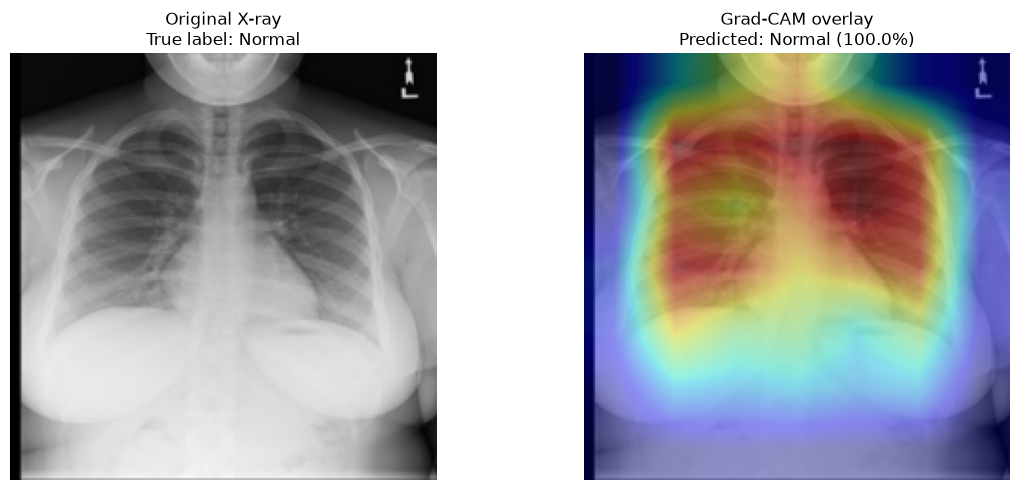

Image: C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\COVID-19_Radiography_Dataset\Normal\images\Normal-4291.png
True label: Normal
Predicted label: Normal

Class probabilities:
Normal: 1.0000
Tuberculosis: 0.0000
COVID-19: 0.0000


In [13]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path

# Dataset and class names
DATA_DIR = Path.cwd() / "Datasets"
test_df = pd.read_csv(DATA_DIR / "test_3class.csv")

CLASS_NAMES = ["Normal", "Tuberculosis", "COVID-19"]
IMAGE_INDEX = 0  # Change this to inspect another test image

# Resolve the image path
image_path = Path(str(test_df.iloc[IMAGE_INDEX]["image_path"]))
if not image_path.is_absolute():
    image_path = Path.cwd() / image_path

# Load image using the same preprocessing approach as training
raw = tf.io.read_file(str(image_path))
raw = tf.io.decode_image(raw, channels=3, expand_animations=False)
raw.set_shape([None, None, 3])

resized = tf.image.resize(raw, (224, 224))
input_batch = tf.expand_dims(tf.cast(resized, tf.float32), axis=0)

# Calculate Grad-CAM for the predicted class
with tf.GradientTape() as tape:
    feature_maps, predictions = grad_model(input_batch, training=False)
    class_index = tf.argmax(predictions[0])
    class_score = predictions[:, class_index]

gradients = tape.gradient(class_score, feature_maps)

if gradients is None:
    raise RuntimeError(
        "Gradients are disconnected. Stop here; do not display a heatmap."
    )

# Average gradients over the spatial dimensions
weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)

# Weighted sum of feature maps
heatmap = tf.reduce_sum(weights * feature_maps, axis=-1)[0]
heatmap = tf.maximum(heatmap, 0)
heatmap = heatmap / (tf.reduce_max(heatmap) + tf.keras.backend.epsilon())
heatmap = heatmap.numpy()

# Resize the heatmap to 224 x 224
heatmap = tf.image.resize(
    heatmap[..., np.newaxis], (224, 224)
).numpy().squeeze()

# Prepare labels and probabilities
probabilities = predictions[0].numpy()
predicted_index = int(class_index.numpy())
predicted_label = CLASS_NAMES[predicted_index]
true_index = int(test_df.iloc[IMAGE_INDEX]["label"])
true_label = CLASS_NAMES[true_index]

# Display original image and overlay
image_display = np.clip(resized.numpy(), 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_display)
plt.title(f"Original X-ray\nTrue label: {true_label}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(image_display)
plt.imshow(heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1)
plt.title(
    f"Grad-CAM overlay\nPredicted: {predicted_label} "
    f"({probabilities[predicted_index]:.1%})"
)
plt.axis("off")

plt.tight_layout()
plt.show()

print("Image:", image_path)
print("True label:", true_label)
print("Predicted label:", predicted_label)
print("\nClass probabilities:")
for name, probability in zip(CLASS_NAMES, probabilities):
    print(f"{name}: {probability:.4f}")


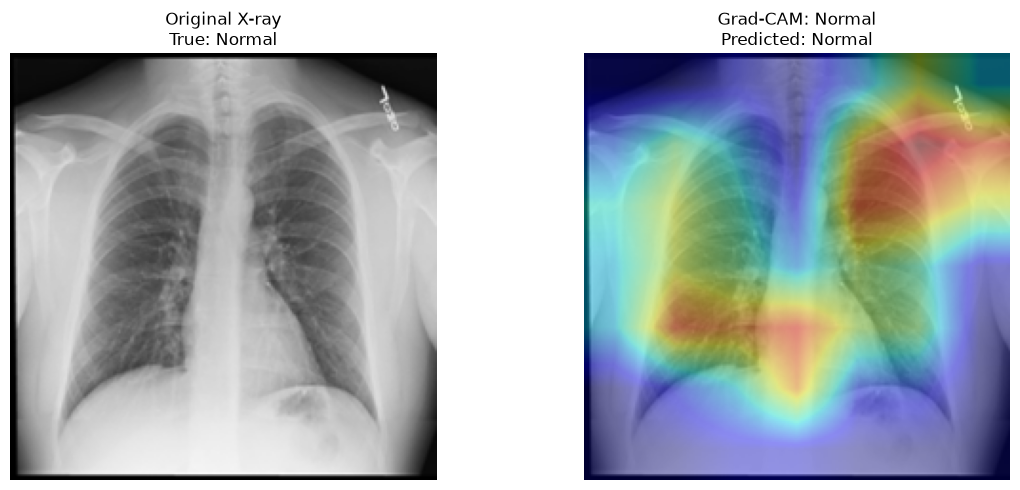

Image: C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\COVID-19_Radiography_Dataset\Normal\images\Normal-6964.png
True label: Normal
Predicted: Normal
Explained class: Normal
Probabilities:
  Normal: 0.998800
  Tuberculosis: 0.000766
  COVID-19: 0.000434


In [14]:

def generate_gradcam(image_index, target_class=None):
    """
    Generate Grad-CAM for a test image.

    target_class:
        None = explain the model's predicted class
        0 = Normal
        1 = Tuberculosis
        2 = COVID-19
    """
    row = test_df.iloc[image_index]
    image_path = Path(str(row["image_path"]))

    if not image_path.is_absolute():
        image_path = Path.cwd() / image_path

    raw = tf.io.read_file(str(image_path))
    raw = tf.io.decode_image(
        raw, channels=3, expand_animations=False
    )
    raw.set_shape([None, None, 3])

    resized = tf.image.resize(raw, (224, 224))
    batch = tf.expand_dims(tf.cast(resized, tf.float32), axis=0)

    with tf.GradientTape() as tape:
        feature_maps, predictions = grad_model(batch, training=False)

        predicted_index = int(tf.argmax(predictions[0]).numpy())
        class_index = (
            predicted_index if target_class is None else int(target_class)
        )

        score = predictions[:, class_index]

    gradients = tape.gradient(score, feature_maps)

    if gradients is None:
        raise RuntimeError("Grad-CAM gradients are disconnected.")

    weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    heatmap = tf.reduce_sum(weights * feature_maps, axis=-1)[0]
    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + tf.keras.backend.epsilon()

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis], (224, 224)
    ).numpy().squeeze()

    probabilities = predictions[0].numpy()
    true_label = CLASS_NAMES[int(row["label"])]

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(np.clip(resized.numpy(), 0, 255).astype(np.uint8))
    axes[0].set_title(f"Original X-ray\nTrue: {true_label}")
    axes[0].axis("off")

    axes[1].imshow(np.clip(resized.numpy(), 0, 255).astype(np.uint8))
    axes[1].imshow(heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1)
    axes[1].set_title(
        f"Grad-CAM: {CLASS_NAMES[class_index]}\n"
        f"Predicted: {CLASS_NAMES[predicted_index]}"
    )
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    print("Image:", image_path)
    print("True label:", true_label)
    print("Predicted:", CLASS_NAMES[predicted_index])
    print("Explained class:", CLASS_NAMES[class_index])
    print("Probabilities:")
    for name, probability in zip(CLASS_NAMES, probabilities):
        print(f"  {name}: {probability:.6f}")


# Try another image after the first successful visualization.
generate_gradcam(image_index=1)



Class: Normal | Test row: 0


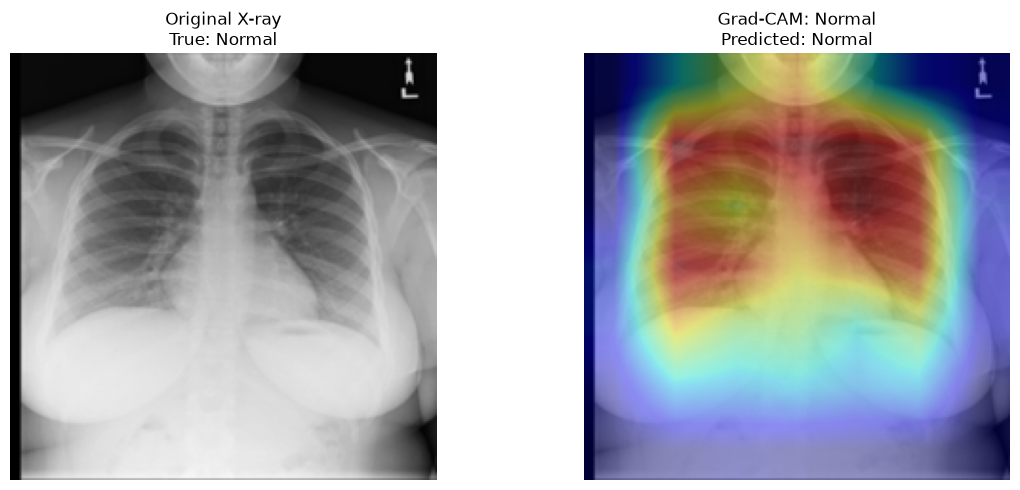

Image: C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\COVID-19_Radiography_Dataset\Normal\images\Normal-4291.png
True label: Normal
Predicted: Normal
Explained class: Normal
Probabilities:
  Normal: 0.999979
  Tuberculosis: 0.000017
  COVID-19: 0.000005

Class: Tuberculosis | Test row: 17


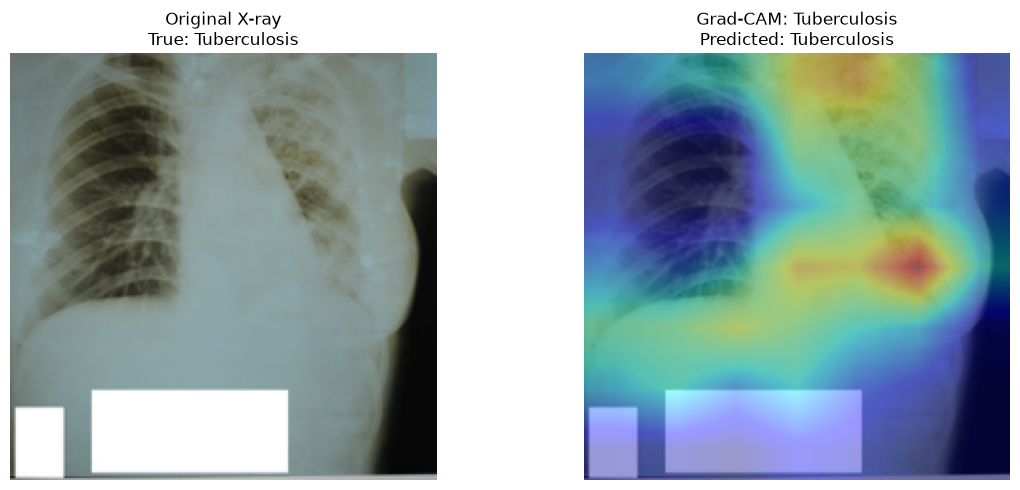

Image: C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\TB_Chest_Radiography_Database\Tuberculosis\Tuberculosis-289.png
True label: Tuberculosis
Predicted: Tuberculosis
Explained class: Tuberculosis
Probabilities:
  Normal: 0.000013
  Tuberculosis: 0.999984
  COVID-19: 0.000003

Class: COVID-19 | Test row: 5


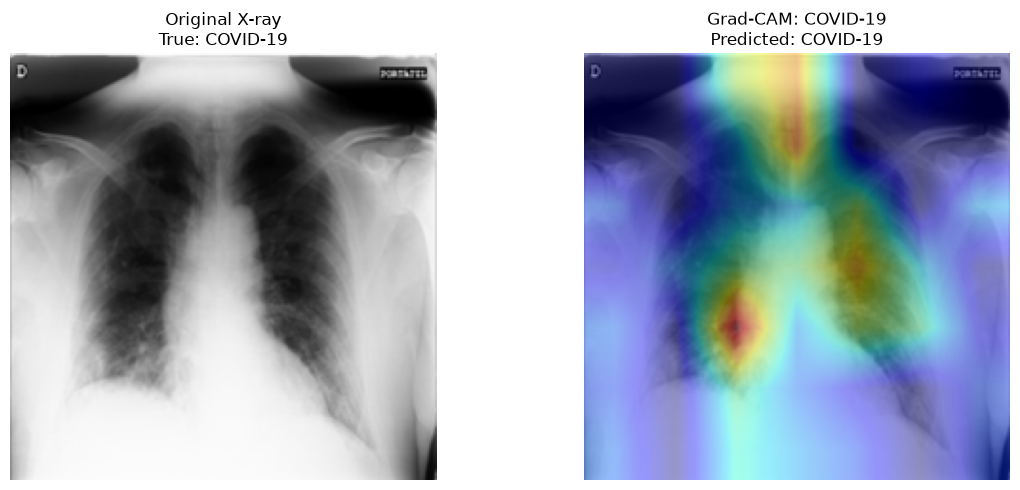

Image: C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\COVID-19_Radiography_Dataset\COVID\images\COVID-2096.png
True label: COVID-19
Predicted: COVID-19
Explained class: COVID-19
Probabilities:
  Normal: 0.028414
  Tuberculosis: 0.004649
  COVID-19: 0.966937


In [15]:

# Find one test image for each class
for class_id, class_name in enumerate(CLASS_NAMES):
    matching_rows = test_df.index[
        test_df["label"] == class_id
    ].tolist()

    if not matching_rows:
        print(f"No test image found for {class_name}")
        continue

    image_index = matching_rows[0]

    print(f"\n{'=' * 45}")
    print(f"Class: {class_name} | Test row: {image_index}")

    # Explain the model's predicted class for this image
    generate_gradcam(image_index=image_index)


In [16]:

import numpy as np

def estimate_uncertainty(image_index):
    """
    Calculate simple uncertainty indicators from the model's
    softmax probabilities. These are not calibrated clinical risks.
    """
    row = test_df.iloc[image_index]

    image_path = Path(str(row["image_path"]))
    if not image_path.is_absolute():
        image_path = Path.cwd() / image_path

    raw = tf.io.read_file(str(image_path))
    raw = tf.io.decode_image(
        raw, channels=3, expand_animations=False
    )
    raw.set_shape([None, None, 3])

    image = tf.image.resize(raw, (224, 224))
    batch = tf.expand_dims(tf.cast(image, tf.float32), axis=0)

    probabilities = model(batch, training=False).numpy()[0]
    probabilities = np.clip(probabilities, 1e-12, 1.0)

    predicted_index = int(np.argmax(probabilities))
    sorted_probs = np.sort(probabilities)[::-1]

    # Simple uncertainty indicators
    entropy = -np.sum(probabilities * np.log(probabilities))
    normalized_entropy = entropy / np.log(len(CLASS_NAMES))
    top_two_margin = sorted_probs[0] - sorted_probs[1]

    print("True label:", CLASS_NAMES[int(row["label"])])
    print("Predicted class:", CLASS_NAMES[predicted_index])
    print("\nClass probabilities:")

    for name, probability in zip(CLASS_NAMES, probabilities):
        print(f"  {name}: {probability:.6f}")

    print(f"\nNormalized entropy: {normalized_entropy:.6f}")
    print(f"Top-two probability margin: {top_two_margin:.6f}")

    return {
        "image_index": image_index,
        "predicted_class": CLASS_NAMES[predicted_index],
        "probabilities": probabilities,
        "normalized_entropy": float(normalized_entropy),
        "top_two_margin": float(top_two_margin)
    }


# Test the uncertainty calculation on the first test image
uncertainty_result = estimate_uncertainty(image_index=0)


True label: Normal
Predicted class: Normal

Class probabilities:
  Normal: 0.999979
  Tuberculosis: 0.000017
  COVID-19: 0.000005

Normalized entropy: 0.000240
Top-two probability margin: 0.999962


In [17]:

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score

# Predict on the complete test dataset
y_true = test_df["label"].to_numpy(dtype=int)
all_probabilities = []

for start in range(0, len(test_df), 32):
    batch_df = test_df.iloc[start:start + 32]
    images = []

    for image_path in batch_df["image_path"].astype(str):
        path = Path(image_path)
        if not path.is_absolute():
            path = Path.cwd() / path

        raw = tf.io.read_file(str(path))
        raw = tf.io.decode_image(
            raw, channels=3, expand_animations=False
        )
        raw.set_shape([None, None, 3])
        images.append(tf.image.resize(raw, (224, 224)))

    batch = tf.cast(tf.stack(images), tf.float32)
    batch_probabilities = model(batch, training=False).numpy()
    all_probabilities.append(batch_probabilities)

probabilities = np.concatenate(all_probabilities, axis=0)
y_pred = probabilities.argmax(axis=1)

# Calculate uncertainty indicators
clipped = np.clip(probabilities, 1e-12, 1.0)
entropy = -np.sum(clipped * np.log(clipped), axis=1)
normalized_entropy = entropy / np.log(len(CLASS_NAMES))

sorted_probabilities = np.sort(probabilities, axis=1)
top_two_margin = sorted_probabilities[:, -1] - sorted_probabilities[:, -2]

results_df = pd.DataFrame({
    "true_label": [CLASS_NAMES[i] for i in y_true],
    "predicted_label": [CLASS_NAMES[i] for i in y_pred],
    "correct": y_true == y_pred,
    "max_probability": probabilities.max(axis=1),
    "normalized_entropy": normalized_entropy,
    "top_two_margin": top_two_margin
})

print("Test samples:", len(results_df))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Misclassified samples:", int((~results_df["correct"]).sum()))

print("\nUncertainty summary by correctness:")
print(
    results_df.groupby("correct")[
        ["max_probability", "normalized_entropy", "top_two_margin"]
    ].mean().round(4)
)

print("\nFive highest-entropy predictions:")
print(
    results_df.nlargest(5, "normalized_entropy")[
        ["true_label", "predicted_label", "correct",
         "max_probability", "normalized_entropy", "top_two_margin"]
    ].to_string(index=False)
)


Test samples: 2702
Accuracy: 0.9652
Misclassified samples: 94

Uncertainty summary by correctness:
         max_probability  normalized_entropy  top_two_margin
correct                                                     
False             0.7380              0.5109          0.4982
True              0.9703              0.0837          0.9443

Five highest-entropy predictions:
  true_label predicted_label  correct  max_probability  normalized_entropy  top_two_margin
      Normal          Normal     True         0.360285            0.998013        0.026931
    COVID-19          Normal    False         0.383268            0.979859        0.003588
    COVID-19          Normal    False         0.409657            0.977560        0.055249
Tuberculosis    Tuberculosis     True         0.462566            0.958955        0.143890
      Normal        COVID-19    False         0.460148            0.928429        0.082534


In [18]:

import numpy as np
import pandas as pd

# Exploratory thresholds only; not clinical cutoffs
PROBABILITY_THRESHOLD = 0.80
ENTROPY_THRESHOLD = 0.40

results_df["review_required"] = (
    (results_df["max_probability"] < PROBABILITY_THRESHOLD)
    | (results_df["normalized_entropy"] > ENTROPY_THRESHOLD)
)

# Confusion counts for detecting model errors
# Positive = prediction is incorrect
actual_error = ~results_df["correct"]
flagged = results_df["review_required"]

true_positive = int((flagged & actual_error).sum())
false_negative = int((~flagged & actual_error).sum())
false_positive = int((flagged & ~actual_error).sum())
true_negative = int((~flagged & ~actual_error).sum())

error_recall = (
    true_positive / (true_positive + false_negative)
    if true_positive + false_negative else 0.0
)

flag_precision = (
    true_positive / (true_positive + false_positive)
    if true_positive + false_positive else 0.0
)

flag_rate = float(flagged.mean())
errors_among_flagged = (
    true_positive / int(flagged.sum())
    if flagged.sum() else 0.0
)

print("Exploratory review-flag evaluation")
print("----------------------------------")
print("Total images:", len(results_df))
print("Total model errors:", int(actual_error.sum()))
print("Images flagged for review:", int(flagged.sum()))
print(f"Review flag rate: {flag_rate:.2%}")
print(f"Error recall: {error_recall:.2%}")
print(f"Flag precision: {flag_precision:.2%}")
print(f"Errors among flagged images: {errors_among_flagged:.2%}")

print("\nCounts:")
print("Errors flagged (true positives):", true_positive)
print("Errors not flagged (false negatives):", false_negative)
print("Correct images flagged:", false_positive)
print("Correct images not flagged:", true_negative)

print("\nFlag rate by true class:")
print(
    results_df.groupby("true_label")["review_required"]
    .agg(["sum", "count", "mean"])
    .assign(flag_rate=lambda x: (100 * x["mean"]).round(2))
    .drop(columns="mean")
)


Exploratory review-flag evaluation
----------------------------------
Total images: 2702
Total model errors: 94
Images flagged for review: 240
Review flag rate: 8.88%
Error recall: 72.34%
Flag precision: 28.33%
Errors among flagged images: 28.33%

Counts:
Errors flagged (true positives): 68
Errors not flagged (false negatives): 26
Correct images flagged: 172
Correct images not flagged: 2436

Flag rate by true class:
              sum  count  flag_rate
true_label                         
COVID-19      106    543      19.52
Normal        129   2054       6.28
Tuberculosis    5    105       4.76


In [19]:

from pathlib import Path

output_dir = Path.cwd() / "uncertainty_analysis"
output_dir.mkdir(parents=True, exist_ok=True)

# Save row-level results, including true/predicted class and review flag
results_path = output_dir / "test_uncertainty_review_results.csv"
results_df.to_csv(results_path, index=False)

# Save a concise metrics summary
summary = pd.DataFrame([{
    "test_samples": len(results_df),
    "model_errors": int((~results_df["correct"]).sum()),
    "flagged_images": int(results_df["review_required"].sum()),
    "review_flag_rate": float(results_df["review_required"].mean()),
    "error_recall": error_recall,
    "flag_precision": flag_precision,
    "errors_among_flagged": errors_among_flagged,
    "probability_threshold": PROBABILITY_THRESHOLD,
    "entropy_threshold": ENTROPY_THRESHOLD
}])

summary_path = output_dir / "review_flag_summary.csv"
summary.to_csv(summary_path, index=False)

print("Saved row-level results to:", results_path)
print("Saved summary to:", summary_path)
print("\nSummary:")
print(summary.to_string(index=False))


Saved row-level results to: c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\uncertainty_analysis\test_uncertainty_review_results.csv
Saved summary to: c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\uncertainty_analysis\review_flag_summary.csv

Summary:
 test_samples  model_errors  flagged_images  review_flag_rate  error_recall  flag_precision  errors_among_flagged  probability_threshold  entropy_threshold
         2702            94             240          0.088823      0.723404        0.283333              0.283333                    0.8                0.4


In [20]:

import json
from datetime import datetime
from pathlib import Path

def generate_research_report(image_index, results_df, test_df):
    """Create a structured, non-diagnostic report for a test image."""

    row = results_df.iloc[image_index]
    image_row = test_df.iloc[image_index]

    report = {
        "report_type": "Experimental AI Research Report",
        "generated_at": datetime.now().isoformat(timespec="seconds"),
        "image_index": int(image_index),
        "image_path": str(image_row["image_path"]),
        "dataset_label_for_evaluation": str(row["true_label"]),
        "model_prediction": str(row["predicted_label"]),
        "class_probabilities": {
            name: float(probabilities[image_index, class_id])
            for class_id, name in enumerate(CLASS_NAMES)
        },
        "uncertainty": {
            "normalized_entropy": float(row["normalized_entropy"]),
            "top_two_margin": float(row["top_two_margin"]),
            "maximum_probability": float(row["max_probability"])
        },
        "review_flag": {
            "review_required": bool(row["review_required"]),
            "reason": (
                "Prediction met the exploratory uncertainty review rule."
                if row["review_required"]
                else "Prediction did not meet the exploratory uncertainty review rule."
            )
        },
        "explainability": {
            "gradcam_available": True,
            "note": (
                "Grad-CAM can be generated separately for this image. "
                "A heatmap does not establish a clinical finding."
            )
        },
        "limitations": [
            "Experimental research output; not a medical diagnosis.",
            "Softmax probabilities are not validated clinical confidence estimates.",
            "The exploratory review thresholds are not clinically validated.",
            "A prediction that is not flagged may still be incorrect.",
            "Clinical interpretation requires an appropriately qualified clinician."
        ]
    }

    return report


# Generate a report for the first test image
report = generate_research_report(
    image_index=0,
    results_df=results_df,
    test_df=test_df
)

print(json.dumps(report, indent=2))

# Save the report as JSON
report_dir = Path.cwd() / "ai_reports"
report_dir.mkdir(parents=True, exist_ok=True)

report_path = report_dir / "research_report_image_0.json"
with open(report_path, "w", encoding="utf-8") as file:
    json.dump(report, file, indent=2)

print("\nReport saved to:", report_path)


{
  "report_type": "Experimental AI Research Report",
  "generated_at": "2026-10-19T14:45:22",
  "image_index": 0,
  "image_path": "C:\\mini project\\TB-Detection-Hybrid-CNN-Transformers-main\\Datasets\\COVID-19_Radiography_Dataset\\Normal\\images\\Normal-4291.png",
  "dataset_label_for_evaluation": "Normal",
  "model_prediction": "Normal",
  "class_probabilities": {
    "Normal": 0.9999785423278809,
    "Tuberculosis": 1.6738351405365393e-05,
    "COVID-19": 4.757549959322205e-06
  },
  "uncertainty": {
    "normalized_entropy": 0.00024016670025704993,
    "top_two_margin": 0.999961793422699,
    "maximum_probability": 0.9999785423278809
  },
  "review_flag": {
    "review_required": false,
    "reason": "Prediction did not meet the exploratory uncertainty review rule."
  },
  "explainability": {
    "gradcam_available": true,
    "note": "Grad-CAM can be generated separately for this image. A heatmap does not establish a clinical finding."
  },
  "limitations": [
    "Experimental re

In [21]:

from pathlib import Path

report_dir = Path.cwd() / "ai_reports"
report_dir.mkdir(parents=True, exist_ok=True)

probabilities = report["class_probabilities"]
uncertainty = report["uncertainty"]
review = report["review_flag"]

text_report = f"""
EXPERIMENTAL CHEST X-RAY AI RESEARCH REPORT
============================================

Generated at: {report["generated_at"]}
Image index: {report["image_index"]}
Image path: {report["image_path"]}

MODEL OUTPUT
------------
Predicted class: {report["model_prediction"]}

Class probabilities (softmax outputs):
- Normal: {probabilities["Normal"]:.6f}
- Tuberculosis: {probabilities["Tuberculosis"]:.6f}
- COVID-19: {probabilities["COVID-19"]:.6f}

UNCERTAINTY INDICATORS
----------------------
Maximum probability: {uncertainty["maximum_probability"]:.6f}
Normalized entropy: {uncertainty["normalized_entropy"]:.6f}
Top-two probability margin: {uncertainty["top_two_margin"]:.6f}

EXPLORATORY REVIEW FLAG
-----------------------
Review required: {review["review_required"]}
Reason: {review["reason"]}

EXPLAINABILITY
--------------
Grad-CAM available: {report["explainability"]["gradcam_available"]}
{report["explainability"]["note"]}

LIMITATIONS
-----------
- This is an experimental research output, not a medical diagnosis.
- Softmax probabilities are not validated clinical confidence estimates.
- The review thresholds have not been clinically validated.
- A prediction that is not flagged may still be incorrect.
- Clinical interpretation requires an appropriately qualified clinician.
"""

text_path = report_dir / f"research_report_image_{report['image_index']}.txt"
text_path.write_text(text_report.strip() + "\n", encoding="utf-8")

print(text_report)
print("\nText report saved to:", text_path)



EXPERIMENTAL CHEST X-RAY AI RESEARCH REPORT

Generated at: 2026-10-19T14:45:22
Image index: 0
Image path: C:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\Datasets\COVID-19_Radiography_Dataset\Normal\images\Normal-4291.png

MODEL OUTPUT
------------
Predicted class: Normal

Class probabilities (softmax outputs):
- Normal: 0.999979
- Tuberculosis: 0.000017
- COVID-19: 0.000005

UNCERTAINTY INDICATORS
----------------------
Maximum probability: 0.999979
Normalized entropy: 0.000240
Top-two probability margin: 0.999962

EXPLORATORY REVIEW FLAG
-----------------------
Review required: False
Reason: Prediction did not meet the exploratory uncertainty review rule.

EXPLAINABILITY
--------------
Grad-CAM available: True
Grad-CAM can be generated separately for this image. A heatmap does not establish a clinical finding.

LIMITATIONS
-----------
- This is an experimental research output, not a medical diagnosis.
- Softmax probabilities are not validated clinical confidence estimates.

In [22]:

import pandas as pd
from pathlib import Path

def compare_model_records(previous_record, current_record):
    """
    Compare two model-output records for the same synthetic example.
    This compares AI outputs, not clinical disease progression.
    """
    previous_probs = previous_record["class_probabilities"]
    current_probs = current_record["class_probabilities"]

    comparison = {
        "record_id": previous_record["record_id"],
        "previous_date": previous_record["date"],
        "current_date": current_record["date"],
        "previous_prediction": previous_record["predicted_class"],
        "current_prediction": current_record["predicted_class"],
        "prediction_changed": (
            previous_record["predicted_class"]
            != current_record["predicted_class"]
        ),
        "probability_changes": {
            name: current_probs[name] - previous_probs[name]
            for name in CLASS_NAMES
        },
        "previous_entropy": previous_record["normalized_entropy"],
        "current_entropy": current_record["normalized_entropy"],
        "entropy_change": (
            current_record["normalized_entropy"]
            - previous_record["normalized_entropy"]
        ),
        "interpretation_note": (
            "This is a comparison of model outputs only. "
            "It does not establish clinical improvement, deterioration, "
            "or disease progression."
        )
    }

    return comparison


# Synthetic example records — not real patient data
previous_record = {
    "record_id": "SYNTHETIC-001",
    "date": "2026-09-01",
    "predicted_class": "Normal",
    "class_probabilities": {
        "Normal": 0.90,
        "Tuberculosis": 0.06,
        "COVID-19": 0.04
    },
    "normalized_entropy": 0.30
}

current_record = {
    "record_id": "SYNTHETIC-001",
    "date": "2026-10-01",
    "predicted_class": "Normal",
    "class_probabilities": {
        "Normal": 0.85,
        "Tuberculosis": 0.10,
        "COVID-19": 0.05
    },
    "normalized_entropy": 0.40
}

comparison = compare_model_records(previous_record, current_record)

print("MODEL OUTPUT COMPARISON")
print("-----------------------")
print("Record:", comparison["record_id"])
print("Previous date:", comparison["previous_date"])
print("Current date:", comparison["current_date"])
print("Previous prediction:", comparison["previous_prediction"])
print("Current prediction:", comparison["current_prediction"])
print("Prediction changed:", comparison["prediction_changed"])

print("\nClass probability changes (current - previous):")
for name, change in comparison["probability_changes"].items():
    print(f"{name}: {change:+.3f}")

print("\nEntropy change:", f'{comparison["entropy_change"]:+.3f}')
print("\nNote:", comparison["interpretation_note"])

# Save comparison
comparison_dir = Path.cwd() / "patient_history_comparison"
comparison_dir.mkdir(parents=True, exist_ok=True)

comparison_path = comparison_dir / "synthetic_record_comparison.csv"

pd.DataFrame([{
    "record_id": comparison["record_id"],
    "previous_date": comparison["previous_date"],
    "current_date": comparison["current_date"],
    "previous_prediction": comparison["previous_prediction"],
    "current_prediction": comparison["current_prediction"],
    "prediction_changed": comparison["prediction_changed"],
    "normal_probability_change": comparison["probability_changes"]["Normal"],
    "tb_probability_change": comparison["probability_changes"]["Tuberculosis"],
    "covid_probability_change": comparison["probability_changes"]["COVID-19"],
    "entropy_change": comparison["entropy_change"],
    "interpretation_note": comparison["interpretation_note"]
}]).to_csv(comparison_path, index=False)

print("\nComparison saved to:", comparison_path)


MODEL OUTPUT COMPARISON
-----------------------
Record: SYNTHETIC-001
Previous date: 2026-09-01
Current date: 2026-10-01
Previous prediction: Normal
Current prediction: Normal
Prediction changed: False

Class probability changes (current - previous):
Normal: -0.050
Tuberculosis: +0.040
COVID-19: +0.010

Entropy change: +0.100

Note: This is a comparison of model outputs only. It does not establish clinical improvement, deterioration, or disease progression.

Comparison saved to: c:\mini project\TB-Detection-Hybrid-CNN-Transformers-main\patient_history_comparison\synthetic_record_comparison.csv


In [23]:

def get_research_status(result_row):
    """
    Assign a research-only status based on the existing review flag.
    This is not a medical triage or referral decision.
    """
    if bool(result_row["review_required"]):
        return {
            "status": "REVIEW_REQUIRED",
            "message": (
                "The model output meets the exploratory review criteria. "
                "Do not rely on this prediction alone."
            )
        }

    return {
        "status": "MODEL_OUTPUT_AVAILABLE",
        "message": (
            "The model output did not meet the exploratory review criteria. "
            "This does not establish that the image is normal or rule out disease."
        )
    }


# Demonstrate the status on the first test record
example_result = results_df.iloc[0]
status = get_research_status(example_result)

print("Research status:", status["status"])
print("Message:", status["message"])

# Summarize the status counts across the test dataset
status_counts = results_df["review_required"].value_counts()

print("\nDataset status summary:")
print("Review required:", int(status_counts.get(True, 0)))
print("Review flag not triggered:", int(status_counts.get(False, 0)))


Research status: MODEL_OUTPUT_AVAILABLE
Message: The model output did not meet the exploratory review criteria. This does not establish that the image is normal or rule out disease.

Dataset status summary:
Review required: 240
Review flag not triggered: 2462
